# **Project Name**    - Predicting Tech Salaries from Glassdoor Job Postings (EDA + Regression)


##### **Project Type**    - EDA + Regression
##### **Contribution**    - Individual
##### **Team Member 1 -** Surya Rohila

# **Project Summary -**

Compensation is one of the most important and least transparent parts of a tech career. Job seekers do not know what to ask for, employers do not know what the market pays, and recruiters struggle to benchmark offers. This project uses 956 job postings scraped from Glassdoor in 2017-2018 (job title, salary estimate, job description, rating, company, location, headquarters, size, founded year, ownership, industry, sector, revenue and competitors) to understand what drives salary in data and analytics roles, and to build a model that predicts the average annual salary of a posting.

**Data preparation.** The raw file reports zero NaN values, but its gaps are hidden behind placeholders such as -1 and "Unknown" (for example 66% of Competitors, 22% of Salary Estimate and 32% of Revenue). 356 rows (37%) were exact duplicates and 214 postings had no salary, so the final dataset has 467 unique, salaried postings. Salary strings such as "$53K-$91K (Glassdoor est.)" and "$21-$34 Per Hour" were parsed into one target, avg_salary, in $K per year (hourly wages were converted using 2,080 working hours). New features were engineered: role family and seniority (from the job title), state, company age, number of competitors, ordinal company size, description length, and 11 skill flags (Python, SQL, R, Spark, AWS, Excel, Tableau, Hadoop, TensorFlow, machine learning, PhD) mined from the job description.

**Key findings.** The average posting pays $101.6K (median $97.5K). Role is the strongest driver: data scientists average $116.9K against $68.9K for data analysts. Pay climbs with seniority, from $68K (junior) to $137K (lead). California postings average $124K against $95K elsewhere, and San Francisco ($134K) pays about $29K more than New York ($105K). Company size shows a U-shape, with very small and very large firms paying more than mid-sized ones, while company rating, age and description length are almost unrelated to pay. Postings that mention machine learning (+$27K), a PhD (+$25K), Python (+$20K) or TensorFlow (+$18K) pay more, while Excel (-$20K) and Tableau (-$8K) signal analyst-type roles. Three hypothesis tests (Welch t-test, Kruskal-Wallis, Mann-Whitney U) confirmed the role, company-size and California effects at the 5% level.

**Modelling.** Three regression models, Ridge, Random Forest and Gradient Boosting, were built inside leakage-safe pipelines (median imputation and scaling fitted on training data only) using an 80/20 split (373 train / 94 test rows). Each was tuned with 5-fold cross-validation (GridSearchCV or RandomizedSearchCV). A mean-prediction baseline has a test MAE of $31.0K. The tuned models reach a test R2 of about 0.44, MAE of about $21.6K-$22.2K and RMSE of about $30K. The three models are effectively tied; Random Forest was chosen because it had the lowest cross-validated MAE ($19.6K). Permutation importance shows that role family, seniority, machine-learning skills and California location matter most, while company-level attributes add little. TF-IDF text features did not improve accuracy and were dropped.

**Business value and limitations.** The model gives job seekers and recruiters a data-driven salary band (typically within about $22K) and shows which skills and roles carry a premium. The main limitations are the small sample, 2017-2018 data, Glassdoor estimates instead of actual pay, and possible overlap between postings of the same company across train and test. More data, current salaries and a Streamlit deployment are natural next steps.

# **GitHub Link -**

Add your GitHub repository link here, for example: `https://github.com/<your-username>/<repository-name>`

# **Problem Statement**


**Salary information for tech roles is scattered and opaque.** Using Glassdoor job postings (2017-2018), this project answers four questions:

1. How does salary vary by job position (for example Data Scientist vs Data Analyst vs Data Engineer)?
2. What is the impact of company size on salary?
3. How do salaries differ by location (for example San Francisco vs New York)?
4. Can a machine-learning model predict the average salary of a job posting from its attributes (role, seniority, location, company details and skills in the description)?

The target variable is `avg_salary` (average of the minimum and maximum salary estimate, in $K per year). Success is measured with MAE / RMSE / R2 against a simple mean-prediction baseline, and by insights that help job seekers, employers, analysts and recruiters.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings('ignore')            # keep the notebook output clean
sns.set_theme(style='whitegrid')             # consistent look for every chart
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
RANDOM_STATE = 42                            # reproducibility for every random operation

### Dataset Loading

In [2]:
# glassdoor_ job.csv file upload from gdrive
! gdown --id 1N5S8w6thJrt9KKTGMUIyuwaAAELdTKQq

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1N5S8w6thJrt9KKTGMUIyuwaAAELdTKQq
To: /content/glassdoor_jobs.csv
100% 3.84M/3.84M [00:00<00:00, 159MB/s]


In [3]:
# Load Dataset
DATA_PATH = 'glassdoor_jobs.csv'

def load_dataset(path):
    """Load the Glassdoor CSV. In Google Colab, ask the user to upload it if it is missing."""
    if not os.path.exists(path):
        try:
            from google.colab import files           # only exists inside Colab
            print('Please upload glassdoor_jobs.csv ...')
            files.upload()
        except ImportError:
            raise FileNotFoundError(f"'{path}' not found. Place the CSV next to this notebook.")
    try:
        return pd.read_csv(path)
    except Exception as err:                         # corrupt file / encoding problem
        raise RuntimeError(f'Could not read {path}: {err}')

df_raw = load_dataset(DATA_PATH)
print('Dataset loaded successfully.')

Dataset loaded successfully.


### Dataset First View

In [4]:
# Dataset First Look
df_raw.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors
0,0,Data Scientist,$53K-$91K (Glassdoor est.),"Data Scientist\nLocation: Albuquerque, NM\nEdu...",3.8,Tecolote Research\n3.8,"Albuquerque, NM","Goleta, CA",501 to 1000 employees,1973,Company - Private,Aerospace & Defense,Aerospace & Defense,$50 to $100 million (USD),-1
1,1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),What You Will Do:\n\nI. General Summary\n\nThe...,3.4,University of Maryland Medical System\n3.4,"Linthicum, MD","Baltimore, MD",10000+ employees,1984,Other Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1
2,2,Data Scientist,$80K-$90K (Glassdoor est.),"KnowBe4, Inc. is a high growth information sec...",4.8,KnowBe4\n4.8,"Clearwater, FL","Clearwater, FL",501 to 1000 employees,2010,Company - Private,Security Services,Business Services,$100 to $500 million (USD),-1
3,3,Data Scientist,$56K-$97K (Glassdoor est.),*Organization and Job ID**\nJob ID: 310709\n\n...,3.8,PNNL\n3.8,"Richland, WA","Richland, WA",1001 to 5000 employees,1965,Government,Energy,"Oil, Gas, Energy & Utilities",$500 million to $1 billion (USD),"Oak Ridge National Laboratory, National Renewa..."
4,4,Data Scientist,$86K-$143K (Glassdoor est.),Data Scientist\nAffinity Solutions / Marketing...,2.9,Affinity Solutions\n2.9,"New York, NY","New York, NY",51 to 200 employees,1998,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,"Commerce Signals, Cardlytics, Yodlee"


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f'Number of rows    : {df_raw.shape[0]}')
print(f'Number of columns : {df_raw.shape[1]}')

Number of rows    : 956
Number of columns : 15


### Dataset Information

In [6]:
# Dataset Info
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 956 entries, 0 to 955
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         956 non-null    int64  
 1   Job Title          956 non-null    object 
 2   Salary Estimate    956 non-null    object 
 3   Job Description    956 non-null    object 
 4   Rating             956 non-null    float64
 5   Company Name       956 non-null    object 
 6   Location           956 non-null    object 
 7   Headquarters       956 non-null    object 
 8   Size               956 non-null    object 
 9   Founded            956 non-null    int64  
 10  Type of ownership  956 non-null    object 
 11  Industry           956 non-null    object 
 12  Sector             956 non-null    object 
 13  Revenue            956 non-null    object 
 14  Competitors        956 non-null    object 
dtypes: float64(1), int64(2), object(12)
memory usage: 112.2+ KB


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
# 'Unnamed: 0' is just the old index, so it is ignored when looking for repeated postings.
dup_count = df_raw.drop(columns=['Unnamed: 0']).duplicated().sum()
print(f'Duplicate rows: {dup_count} ({dup_count / len(df_raw):.1%} of the data)')

Duplicate rows: 356 (37.2% of the data)


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print('--- Real NaN values ---')
print(df_raw.isnull().sum().to_string())

# Glassdoor hides missing information behind placeholders (-1, 'Unknown'), so NaN counts alone are misleading.
PLACEHOLDERS = ['-1', '-1.0', 'Unknown', 'Unknown / Non-Applicable']
placeholder_counts = {col: int(df_raw[col].astype(str).isin(PLACEHOLDERS).sum()) for col in df_raw.columns}
placeholder_counts = pd.Series(placeholder_counts)
print('\n--- Hidden missing values (placeholders such as -1 / Unknown) ---')
print(placeholder_counts[placeholder_counts > 0].sort_values(ascending=False).to_string())

--- Real NaN values ---
Unnamed: 0           0
Job Title            0
Salary Estimate      0
Job Description      0
Rating               0
Company Name         0
Location             0
Headquarters         0
Size                 0
Founded              0
Type of ownership    0
Industry             0
Sector               0
Revenue              0
Competitors          0

--- Hidden missing values (placeholders such as -1 / Unknown) ---
Competitors          634
Revenue              310
Salary Estimate      214
Founded               97
Industry              39
Sector                39
Rating                34
Size                  26
Type of ownership     22
Headquarters          11


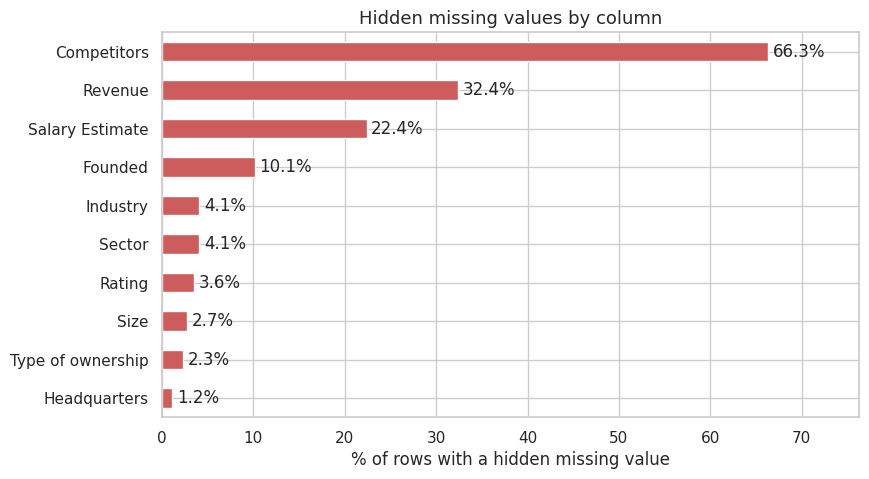

In [9]:
# Visualizing the missing values (placeholders converted to NaN)
hidden_missing_pct = (placeholder_counts[placeholder_counts > 0] / len(df_raw) * 100).sort_values()
plt.figure(figsize=(9, 5))
ax = hidden_missing_pct.plot(kind='barh', color='indianred')
for i, v in enumerate(hidden_missing_pct):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.xlabel('% of rows with a hidden missing value')
plt.title('Hidden missing values by column')
plt.xlim(0, hidden_missing_pct.max() + 10)
plt.show()

### What did you know about your dataset?

* The dataset has **956 rows and 15 columns**: 12 text/categorical columns, 2 numeric columns (`Rating`, `Founded`) and an unused index column (`Unnamed: 0`).
* There are **no real NaN values**, but missing data is hidden behind placeholders: `-1` or `Unknown`. The worst columns are `Competitors` (634 rows, 66%), `Revenue` (310, 32%), `Salary Estimate` (214, 22%) and `Founded` (97, 10%).
* **356 rows (37%) are duplicates**, because the same posting was scraped several times. Keeping them would let identical rows appear in both train and test data and inflate model scores.
* The target (salary) exists only inside the text column `Salary Estimate`, in mixed formats (`$53K-$91K`, `$21-$34 Per Hour`, `Employer Provided Salary:...`), so it needs parsing.
* `Company Name` carries the rating glued on after a newline, and `Job Description` is long free text that can be mined for skills.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
list(df_raw.columns)

['Unnamed: 0',
 'Job Title',
 'Salary Estimate',
 'Job Description',
 'Rating',
 'Company Name',
 'Location',
 'Headquarters',
 'Size',
 'Founded',
 'Type of ownership',
 'Industry',
 'Sector',
 'Revenue',
 'Competitors']

In [11]:
# Dataset Describe
print('--- Numerical columns ---')
print(df_raw.describe().T.to_string())
print('\n--- Text / categorical columns ---')
df_raw.describe(include=['object', 'string']).T

--- Numerical columns ---
            count         mean         std  min      25%     50%      75%     max
Unnamed: 0  956.0   477.500000  276.117729  0.0   238.75   477.5   716.25   955.0
Rating      956.0     3.601255    1.067619 -1.0     3.30     3.8     4.20     5.0
Founded     956.0  1774.605649  598.942517 -1.0  1937.00  1992.0  2008.00  2019.0

--- Text / categorical columns ---


,count,unique,top,freq
Job Title,956,328,Data Scientist,178
Salary Estimate,956,417,-1,214
Job Description,956,596,Data Engineer with R\n\n-Contract Role in Atla...,4
Company Name,956,448,Takeda Pharmaceuticals\n3.7,14
Location,956,237,"New York, NY",78
Headquarters,956,235,"New York, NY",75
Size,956,9,1001 to 5000 employees,177
Type of ownership,956,13,Company - Private,532
Industry,956,63,Biotech & Pharmaceuticals,148
Sector,956,25,Information Technology,239


### Variables Description

| Column | Meaning |
|---|---|
| Job Title | Title of the posting (328 distinct values) |
| Salary Estimate | Salary range as text (annual `K` or hourly) - source of the target |
| Job Description | Full text of the posting |
| Rating | Glassdoor company rating (1-5, `-1` = missing) |
| Company Name | Company (rating appended after a line break) |
| Location / Headquarters | City, state of the job and of the company HQ |
| Size | Number of employees (ordered buckets) |
| Founded | Year the company was founded (`-1` = missing) |
| Type of ownership | Private, public, nonprofit, government, etc. |
| Industry / Sector | Business area (63 industries, 25 sectors) |
| Revenue | Company revenue bucket |
| Competitors | Competing companies (`-1` = none listed) |

**Features created during wrangling:** `avg_salary` (target), `job_category`, `seniority`, `state`, `same_state`, `company_age`, `num_comp`, `size_ord`, `revenue_ord`, `desc_len` and 11 skill flags (`python`, `sql`, `r_lang`, `spark`, `aws`, `excel`, `tableau`, `hadoop`, `tensorflow`, `machine_learning`, `phd`).

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in df_raw.columns:
    print(f'{col:<20} -> {df_raw[col].nunique():>4} unique values')

Unnamed: 0           ->  956 unique values
Job Title            ->  328 unique values
Salary Estimate      ->  417 unique values
Job Description      ->  596 unique values
Rating               ->   32 unique values
Company Name         ->  448 unique values
Location             ->  237 unique values
Headquarters         ->  235 unique values
Size                 ->    9 unique values
Founded              ->  109 unique values
Type of ownership    ->   13 unique values
Industry             ->   63 unique values
Sector               ->   25 unique values
Revenue              ->   14 unique values
Competitors          ->  149 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.

# ---------- 1. Reusable helper functions (kept modular so each step is easy to test) ----------
SIZE_ORDER = ['1 to 50 employees', '51 to 200 employees', '201 to 500 employees', '501 to 1000 employees',
              '1001 to 5000 employees', '5001 to 10000 employees', '10000+ employees']
REV_ORDER = ['Less than $1 million (USD)', '$1 to $5 million (USD)', '$5 to $10 million (USD)',
             '$10 to $25 million (USD)', '$25 to $50 million (USD)', '$50 to $100 million (USD)',
             '$100 to $500 million (USD)', '$500 million to $1 billion (USD)', '$1 to $2 billion (USD)',
             '$2 to $5 billion (USD)', '$5 to $10 billion (USD)', '$10+ billion (USD)']
SENIORITY_ORDER = ['junior', 'mid', 'senior', 'lead', 'manager']
STATE_FIX = {'Virginia': 'VA', 'Oregon': 'OR', 'New Jersey': 'NJ', 'Maryland': 'MD', 'Michigan': 'MI'}

# regex patterns used to flag skills mentioned in the job description
SKILL_PATTERNS = {
    'python': r'\bpython\b', 'sql': r'\bsql\b', 'r_lang': r'\bR\b(?!&)', 'spark': r'\bspark\b',
    'aws': r'\baws\b', 'excel': r'\bexcel\b', 'tableau': r'\btableau\b', 'hadoop': r'\bhadoop\b',
    'tensorflow': r'\btensorflow\b', 'machine_learning': r'machine learning', 'phd': r'ph\.?d',
}
SKILL_COLS = list(SKILL_PATTERNS)

def parse_salary(text):
    """'$53K-$91K (Glassdoor est.)' or '$21-$34 Per Hour' -> (min, max) in $ thousands per year."""
    if not isinstance(text, str) or text.strip() == '-1':
        return (np.nan, np.nan)
    nums = [float(n) for n in re.findall(r'\$(\d+(?:\.\d+)?)', text)]
    if len(nums) < 2:
        return (np.nan, np.nan)
    low, high = nums[0], nums[1]
    if 'per hour' in text.lower():                  # hourly wage -> annual (2080 working hours)
        low, high = low * 2080 / 1000, high * 2080 / 1000
    return (low, high)

def simplify_title(title):
    """Collapse hundreds of raw job titles into a few role families."""
    t = title.lower()
    if 'machine learning' in t or 'ml engineer' in t: return 'ml engineer'
    if 'data scien' in t:                              return 'data scientist'
    if 'data engineer' in t:                           return 'data engineer'
    if 'analyst' in t or 'analytics' in t or 'bi ' in t or 'business intelligence' in t: return 'analyst'
    if 'scientist' in t or 'research' in t:            return 'other scientist'
    return 'other'

def get_seniority(title):
    """Seniority level read from the job title."""
    t = title.lower()
    if re.search(r'manager|director|head of|\bvp\b|chief', t): return 'manager'
    if re.search(r'lead|principal|staff', t):                  return 'lead'
    if re.search(r'senior|\bsr\b|\bsr\.', t):                  return 'senior'
    if re.search(r'junior|\bjr\b|associate|entry', t):         return 'junior'
    return 'mid'

def get_state(location):
    """'Albuquerque, NM' -> 'NM'. Locations without a comma are mapped or marked Unspecified."""
    if ',' in location:
        return location.split(',')[-1].strip()
    return STATE_FIX.get(location.strip(), 'Unspecified')

def make_analysis_ready(raw):
    """Full cleaning pipeline: raw Glassdoor dataframe -> analysis ready dataframe."""
    d = raw.drop(columns=['Unnamed: 0'], errors='ignore').drop_duplicates().reset_index(drop=True)

    # --- placeholders -> real NaN ---
    for col in ['Headquarters', 'Size', 'Type of ownership', 'Industry', 'Sector', 'Revenue']:
        d[col] = d[col].replace(['-1', 'Unknown', 'Unknown / Non-Applicable'], np.nan)
    d['Rating'] = d['Rating'].replace(-1, np.nan)
    d['Founded'] = d['Founded'].replace(-1, np.nan)

    # --- target variable ---
    d[['min_salary', 'max_salary']] = d['Salary Estimate'].apply(lambda s: pd.Series(parse_salary(s)))
    d['avg_salary'] = (d['min_salary'] + d['max_salary']) / 2
    d['hourly'] = d['Salary Estimate'].str.contains('Per Hour', case=False).astype(int)
    d['employer_provided'] = d['Salary Estimate'].str.contains('Employer', case=False).astype(int)
    d = d.dropna(subset=['avg_salary']).reset_index(drop=True)      # a row without a salary cannot be used

    # --- company / location features ---
    d['company_name'] = d['Company Name'].str.split('\n').str[0].str.strip()
    d['state'] = d['Location'].apply(get_state)
    d['hq_state'] = d['Headquarters'].fillna('').apply(lambda x: x.split(',')[-1].strip() if ',' in x else np.nan)
    d['same_state'] = (d['state'] == d['hq_state']).astype(int)
    d['company_age'] = (2018 - d['Founded']).clip(lower=0)             # data was scraped in 2017-2018
    d['num_comp'] = d['Competitors'].apply(lambda x: 0 if x == '-1' else len(x.split(',')))
    d['size_ord'] = d['Size'].map({s: i for i, s in enumerate(SIZE_ORDER)})
    d['revenue_ord'] = d['Revenue'].map({s: i for i, s in enumerate(REV_ORDER)})

    # --- job title / description features ---
    d['job_category'] = d['Job Title'].apply(simplify_title)
    d['seniority'] = d['Job Title'].apply(get_seniority)
    d['desc_len'] = d['Job Description'].str.len()
    for skill, pattern in SKILL_PATTERNS.items():
        flags = (re.IGNORECASE if skill != 'r_lang' else 0)             # 'R' must be case sensitive
        d[skill] = d['Job Description'].apply(lambda x: int(bool(re.search(pattern, x, flags))))
    return d

df = make_analysis_ready(df_raw)
print(f'Raw rows: {len(df_raw)}  ->  analysis-ready rows: {len(df)}  (duplicates and rows without salary removed)')
print(f"Hourly salaries converted to annual: {df['hourly'].sum()} rows")
df[['Job Title', 'job_category', 'seniority', 'state', 'min_salary', 'max_salary', 'avg_salary']].head()

Raw rows: 956  ->  analysis-ready rows: 467  (duplicates and rows without salary removed)
Hourly salaries converted to annual: 10 rows


,Job Title,job_category,seniority,state,min_salary,max_salary,avg_salary
0,Data Scientist,data scientist,mid,NM,53.0,91.0,72.0
1,Healthcare Data Scientist,data scientist,mid,MD,63.0,112.0,87.5
2,Data Scientist,data scientist,mid,FL,80.0,90.0,85.0
3,Data Scientist,data scientist,mid,WA,56.0,97.0,76.5
4,Data Scientist,data scientist,mid,NY,86.0,143.0,114.5


### What all manipulations have you done and insights you found?

1. Dropped the index column and **356 duplicate rows** (956 -> 600).
2. Converted placeholders (`-1`, `Unknown`) into real `NaN`.
3. **Parsed salary** text into min / max / average in $K per year; hourly wages were multiplied by 2,080 hours (10 rows). Rows with no salary (133 after de-duplication) were dropped because a target cannot be imputed honestly -> **467 rows**.
4. Cleaned the company name, extracted `state`, built `same_state`, `company_age` (2018 minus founded year), `num_comp`, and ordinal `size_ord` / `revenue_ord`.
5. Simplified 328 raw job titles into **6 role families** and **5 seniority levels**.
6. Created **11 skill flags** and `desc_len` from the job description.

**Insights:** salary is right-skewed (mean $101.6K, median $97.5K); data scientists are the largest group (205 of 467); about 61% of postings list no competitors, so `num_comp` is mostly zero.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

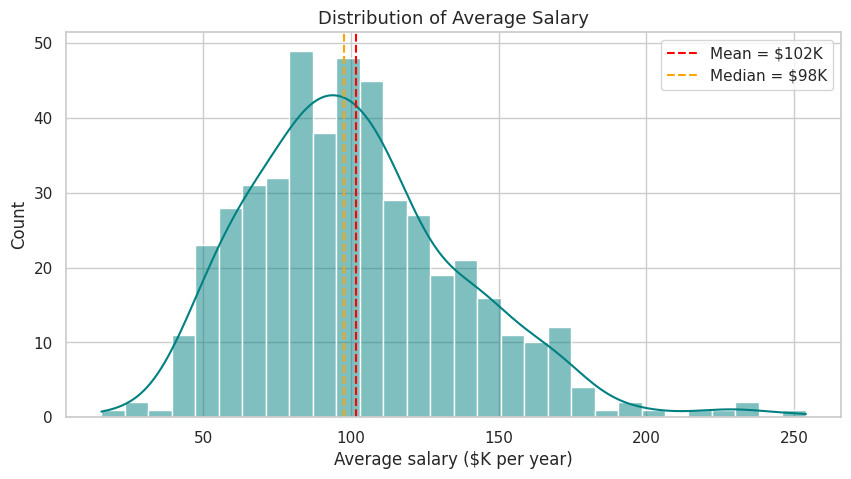

Skewness: 0.78


In [14]:
# Chart - 1 visualization code
# Distribution of the target variable (average salary)
plt.figure(figsize=(10, 5))
sns.histplot(df['avg_salary'], bins=30, kde=True, color='teal')
plt.axvline(df['avg_salary'].mean(), color='red', ls='--', label=f"Mean = ${df['avg_salary'].mean():.0f}K")
plt.axvline(df['avg_salary'].median(), color='orange', ls='--', label=f"Median = ${df['avg_salary'].median():.0f}K")
plt.title('Distribution of Average Salary')
plt.xlabel('Average salary ($K per year)')
plt.legend()
plt.show()
print(f"Skewness: {df['avg_salary'].skew():.2f}")

##### 1. Why did you pick the specific chart?

A histogram with a KDE curve is the standard way to see the shape, spread and skew of one numeric variable - here the target `avg_salary`.

##### 2. What is/are the insight(s) found from the chart?

Salary is right-skewed (skewness 0.78): the mean ($101.6K) sits above the median ($97.5K). Half of all postings fall between about $76K and $121K, with a long tail up to $254K.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** employers and job seekers get a realistic range ($76K-$121K) instead of a single number. **Caution:** 8 postings above $188K pull the mean up, so quoting the mean would overstate what a typical role pays; medians or ranges are safer.

#### Chart - 2

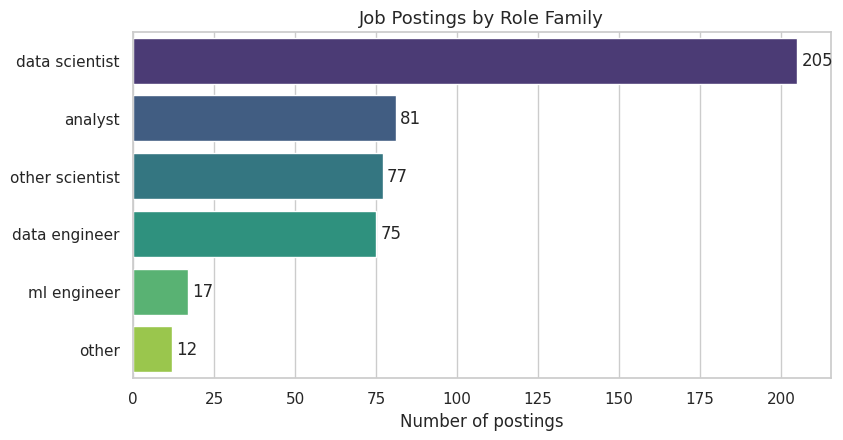

In [15]:
# Chart - 2 visualization code
# Number of postings per role family
order = df['job_category'].value_counts().index
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=df, y='job_category', order=order, palette='viridis')
for c in ax.containers:
    ax.bar_label(c, padding=3)
plt.title('Job Postings by Role Family')
plt.xlabel('Number of postings'); plt.ylabel('')
plt.show()

##### 1. Why did you pick the specific chart?

A count bar chart is the clearest way to compare how many postings fall in each category of role family.

##### 2. What is/are the insight(s) found from the chart?

Data Scientist roles dominate (205 postings, 44%), followed by Data Analyst (81), other scientist roles (77) and Data Engineer (75). ML Engineer (17) and 'other' (12) are rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** demand is concentrated in data science, so training programmes and job seekers can target it. **Negative:** the small ML Engineer sample (17) makes any salary estimate for that group less reliable.

#### Chart - 3

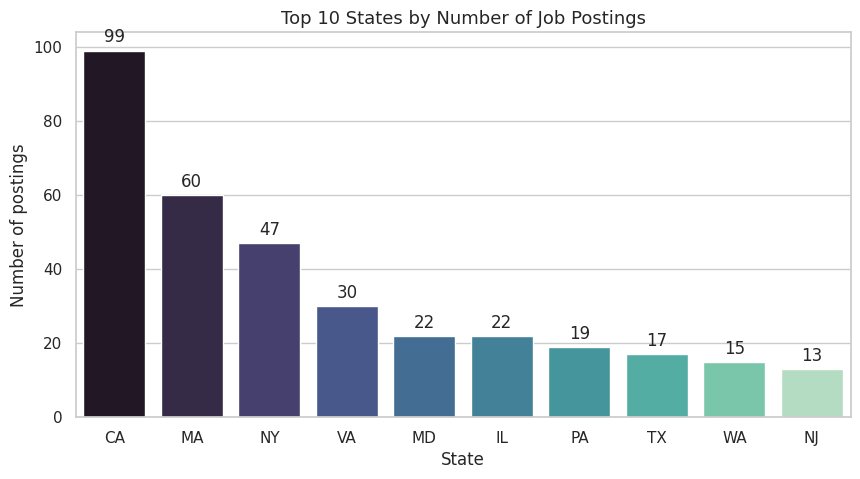

In [16]:
# Chart - 3 visualization code
# Where are the jobs? Top 10 states by number of postings
top_states = df['state'].value_counts().head(10)
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_states.index, y=top_states.values, palette='mako')
for c in ax.containers:
    ax.bar_label(c, padding=3)
plt.title('Top 10 States by Number of Job Postings')
plt.xlabel('State'); plt.ylabel('Number of postings')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of the top 10 states shows where hiring is concentrated and is easy to read with the counts on top.

##### 2. What is/are the insight(s) found from the chart?

California leads with 99 postings (21%), then Massachusetts (60) and New York (47). These three states hold 44% of all postings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** recruiters and candidates know which hubs have the most opportunities. **Negative:** heavy concentration means strong competition for talent and high living costs in those states; the data says nothing about remote work.

#### Chart - 4

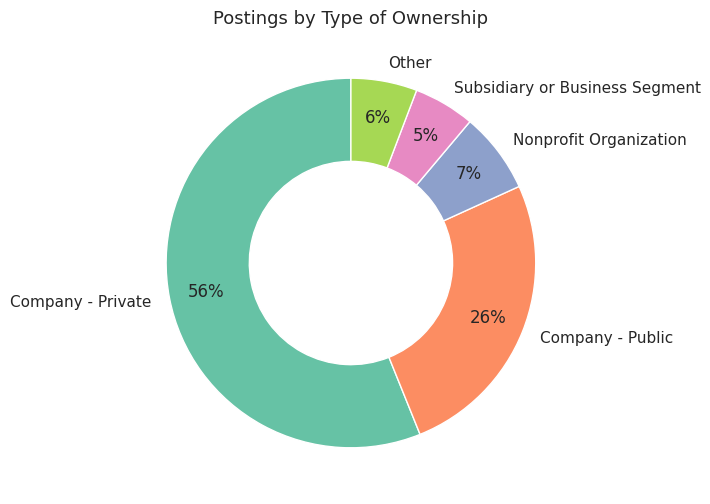

In [17]:
# Chart - 4 visualization code
# Share of postings by type of ownership (small groups merged into "Other")
own = df['Type of ownership'].fillna('Unknown').value_counts()
main = own[own / own.sum() >= 0.03]
own_plot = pd.concat([main, pd.Series({'Other': own.drop(main.index).sum()})])
plt.figure(figsize=(8, 6))
plt.pie(own_plot, labels=own_plot.index, autopct='%1.0f%%', startangle=90, pctdistance=0.8,
        wedgeprops=dict(width=0.45, edgecolor='white'), colors=sns.color_palette('Set2'))
plt.title('Postings by Type of Ownership')
plt.show()

##### 1. Why did you pick the specific chart?

A donut chart shows each ownership type as a share of the whole, which suits a few categories that add up to 100%.

##### 2. What is/are the insight(s) found from the chart?

Private companies account for 56% of postings, public companies 26%, nonprofits 7% and subsidiaries 5%. Government, hospitals, universities and others make up the remaining 6%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** private and public firms are where most data jobs are, so job seekers should focus there. **Negative:** government, hospital and university groups are so small that conclusions about their pay would be unreliable.

#### Chart - 5

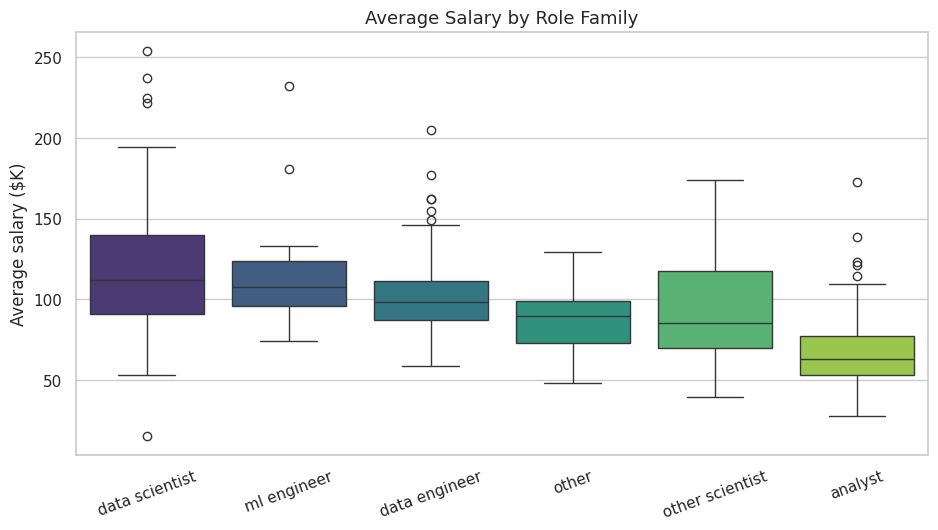

,count,mean,median
job_category,,,
data scientist,205,116.9,112.0
ml engineer,17,116.9,107.5
data engineer,75,102.9,98.5
other,12,86.5,89.5
other scientist,77,92.7,85.5
analyst,81,68.9,63.0


In [18]:
# Chart - 5 visualization code
# Salary by role family (answers: how does salary vary by job position?)
order = df.groupby('job_category')['avg_salary'].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 5.5))
sns.boxplot(data=df, x='job_category', y='avg_salary', order=order, palette='viridis')
plt.title('Average Salary by Role Family')
plt.xlabel(''); plt.ylabel('Average salary ($K)')
plt.xticks(rotation=20)
plt.show()
df.groupby('job_category')['avg_salary'].agg(['count', 'mean', 'median']).round(1).sort_values('median', ascending=False)

##### 1. Why did you pick the specific chart?

A box plot compares the salary distribution across role families and shows medians, spread and outliers in one view. It answers the question 'how does salary vary by job position?'.

##### 2. What is/are the insight(s) found from the chart?

Data Scientists have the highest typical pay (median $112K) and ML Engineers are similar (median $107.5K, mean $116.9K). Data Engineers follow (median $98.5K), then other scientist roles ($85.5K). **Data Analysts earn the least (median $63K)** - about $49K below data scientists.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** role is the biggest salary lever, so analysts can plan upskilling (Python, ML) toward higher-paid roles and employers can benchmark offers by role. **Negative:** analyst pay is far below the rest, which creates a retention risk for employers who do not budget for skill growth.

#### Chart - 6

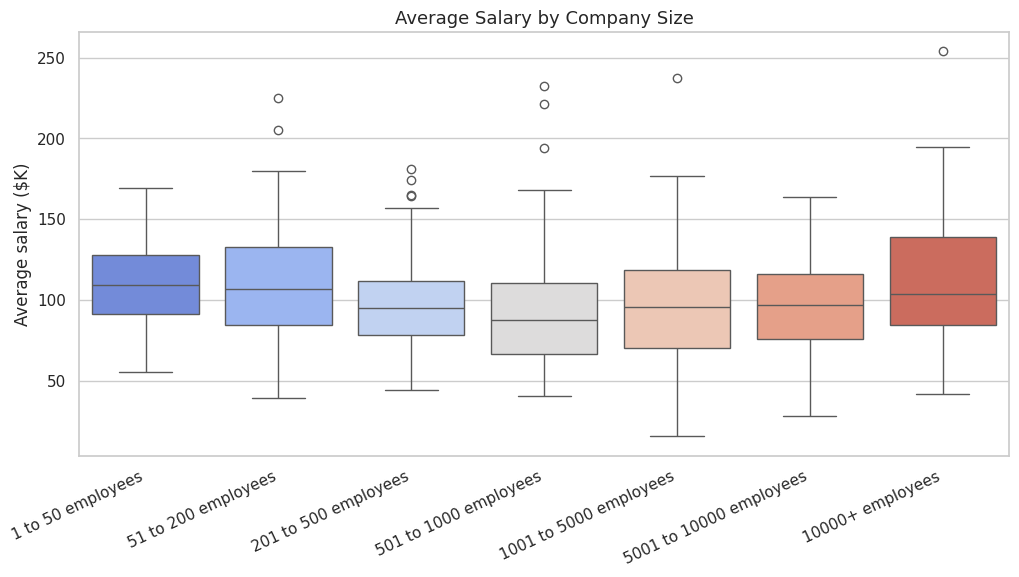

,count,mean,median
Size,,,
1 to 50 employees,24,108.3,109.0
51 to 200 employees,61,108.2,106.5
201 to 500 employees,77,97.8,95.0
501 to 1000 employees,80,95.1,87.2
1001 to 5000 employees,93,97.0,95.5
5001 to 10000 employees,46,97.2,96.8
10000+ employees,80,110.5,103.5


In [19]:
# Chart - 6 visualization code
# Salary by company size (answers: what is the impact of company size?)
size_present = [s for s in SIZE_ORDER if s in df['Size'].unique()]
plt.figure(figsize=(12, 5.5))
sns.boxplot(data=df.dropna(subset=['Size']), x='Size', y='avg_salary', order=size_present, palette='coolwarm')
plt.title('Average Salary by Company Size')
plt.xlabel(''); plt.ylabel('Average salary ($K)')
plt.xticks(rotation=25, ha='right')
plt.show()
df.groupby('Size')['avg_salary'].agg(['count', 'mean', 'median']).reindex(size_present).round(1)

##### 1. Why did you pick the specific chart?

A box plot with ordered size buckets shows whether salary rises with company size and how wide the spread is inside each bucket.

##### 2. What is/are the insight(s) found from the chart?

The pattern is **not a straight line but U-shaped**: companies with 1-200 employees (median about $107-109K) and 10,000+ employees (median $103.5K) pay more than mid-sized firms of 201-1,000 employees (median $87K-$95K). The 501-1000 group has the lowest median ($87.2K).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** startups and very large firms can use pay as a hiring tool, and candidates should not rule out small companies. **Negative:** mid-sized employers risk losing talent to both ends. Size alone is a weak predictor (correlation with salary is about 0.01).

#### Chart - 7

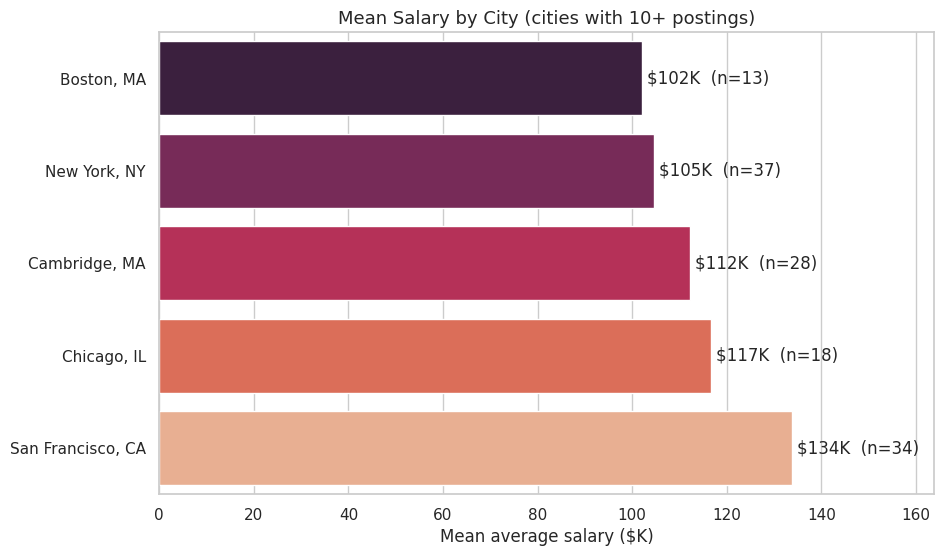

In [20]:
# Chart - 7 visualization code
# Salary by city (answers: how do salaries differ by location?) - cities with at least 10 postings
city_stats = df.groupby('Location')['avg_salary'].agg(['count', 'mean']).query('count >= 10').sort_values('mean')
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=city_stats['mean'], y=city_stats.index, palette='rocket')
for i, (m, n) in enumerate(zip(city_stats['mean'], city_stats['count'])):
    ax.text(m + 1, i, f'${m:.0f}K  (n={n})', va='center')
plt.title('Mean Salary by City (cities with 10+ postings)')
plt.xlabel('Mean average salary ($K)'); plt.ylabel('')
plt.xlim(0, city_stats['mean'].max() + 30)
plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart of mean salary by city, with the sample size printed beside each bar, shows how location changes pay while making small samples visible.

##### 2. What is/are the insight(s) found from the chart?

San Francisco pays the most ($133.8K, 34 postings), followed by Chicago ($116.6K), Cambridge MA ($112.3K), New York ($104.7K) and Boston ($102.0K). San Francisco pays about $29K more than New York. Austin has only 5 postings (mean $114K), below the 10-posting threshold, so it is not charted.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** location-adjusted salary benchmarks help employers stay competitive and help candidates negotiate. **Negative:** the higher pay in San Francisco is probably offset by living costs, which this dataset does not include, so the numbers should not be read as better purchasing power.

#### Chart - 8

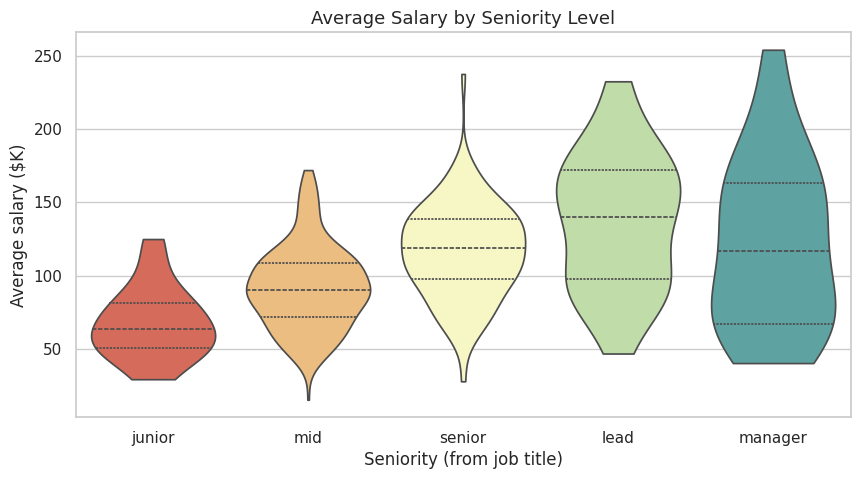

,count,mean,median
seniority,,,
junior,16,68.0,64.0
mid,294,92.4,90.5
senior,97,116.6,119.0
lead,36,137.4,140.2
manager,24,121.9,117.0


In [21]:
# Chart - 8 visualization code
# Salary by seniority level
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x='seniority', y='avg_salary', order=SENIORITY_ORDER, palette='Spectral', inner='quartile', cut=0)
plt.title('Average Salary by Seniority Level')
plt.xlabel('Seniority (from job title)'); plt.ylabel('Average salary ($K)')
plt.show()
df.groupby('seniority')['avg_salary'].agg(['count', 'mean', 'median']).reindex(SENIORITY_ORDER).round(1)

##### 1. Why did you pick the specific chart?

A violin plot with quartiles shows both the distribution shape and the central values for each seniority level, which a bar of averages would hide.

##### 2. What is/are the insight(s) found from the chart?

Pay rises step by step: junior $68K (n=16), mid $92K (n=294), senior $117K (n=97) and lead $137K (n=36). Managers ($122K) earn less on average than leads.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a clear ladder of roughly +$21K to +$24K per step helps with career planning and salary banding. **Caution:** 63% of postings are labelled 'mid' simply because the title shows no level, and the junior group is small. Lead roles out-earning managers suggests that the technical track can pay as well as management.

#### Chart - 9

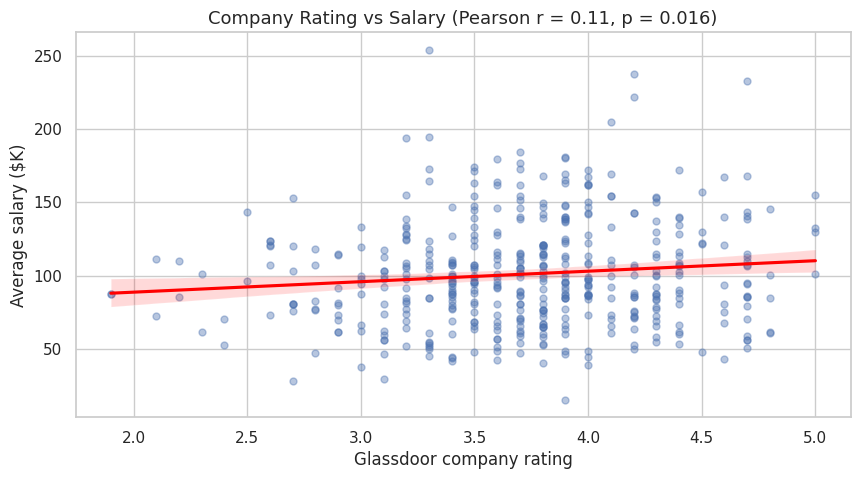

In [22]:
# Chart - 9 visualization code
# Company rating vs salary (numerical vs numerical)
rated = df.dropna(subset=['Rating'])
r, p = stats.pearsonr(rated['Rating'], rated['avg_salary'])
plt.figure(figsize=(10, 5))
sns.regplot(data=rated, x='Rating', y='avg_salary', scatter_kws={'alpha': 0.4, 's': 25}, line_kws={'color': 'red'})
plt.title(f'Company Rating vs Salary (Pearson r = {r:.2f}, p = {p:.3f})')
plt.xlabel('Glassdoor company rating'); plt.ylabel('Average salary ($K)')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with a regression line is the standard tool for the relationship between two numeric variables (company rating and salary).

##### 2. What is/are the insight(s) found from the chart?

There is only a **weak positive relationship** (Pearson r = 0.11, p = 0.016). Highly rated companies pay slightly more on average, but rating explains very little of the variation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** employers cannot rely on pay alone to improve ratings and should look at culture too. **Negative:** using rating as a salary indicator would mislead; a good rating is not a sign of high pay.

#### Chart - 10

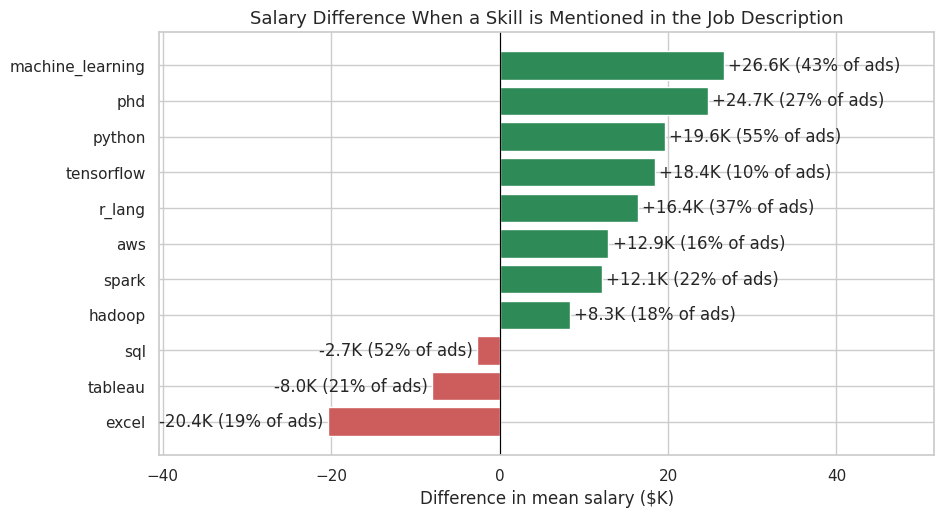

In [23]:
# Chart - 10 visualization code
# Skill premium: mean salary of postings that mention a skill minus those that do not
premium = {}
for skill in SKILL_COLS:
    with_skill = df.loc[df[skill] == 1, 'avg_salary'].mean()
    without = df.loc[df[skill] == 0, 'avg_salary'].mean()
    premium[skill] = (with_skill - without, df[skill].mean() * 100)
premium_df = pd.DataFrame(premium, index=['premium', 'share_pct']).T.sort_values('premium')
colors = ['seagreen' if v > 0 else 'indianred' for v in premium_df['premium']]
plt.figure(figsize=(10, 5.5))
ax = plt.barh(premium_df.index, premium_df['premium'], color=colors)
for i, (v, s) in enumerate(zip(premium_df['premium'], premium_df['share_pct'])):
    plt.text(v + (0.5 if v >= 0 else -0.5), i, f'{v:+.1f}K ({s:.0f}% of ads)', va='center', ha='left' if v >= 0 else 'right')
plt.axvline(0, color='black', lw=0.8)
plt.title('Salary Difference When a Skill is Mentioned in the Job Description')
plt.xlabel('Difference in mean salary ($K)')
plt.xlim(premium_df['premium'].min() - 20, premium_df['premium'].max() + 25)
plt.show()

##### 1. Why did you pick the specific chart?

A diverging horizontal bar chart of 'salary with the skill minus salary without it' shows at a glance which skills carry a premium and which go with lower pay.

##### 2. What is/are the insight(s) found from the chart?

Postings mentioning **machine learning (+$26.6K), a PhD (+$24.7K), Python (+$19.6K), TensorFlow (+$18.4K) and R (+$16.4K)** pay clearly more. Spark, AWS and Hadoop add $8K-$13K. **Excel (-$20.4K) and Tableau (-$8.0K)** go with lower pay and SQL is neutral (-$2.7K), even though SQL appears in 52% of ads.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a concrete upskilling map for candidates and a pay-benchmark guide for employers. **Caution:** this is correlation, not causation - Excel and Tableau appear mostly in analyst postings, so the negative numbers partly reflect the role, not the tool itself.

#### Chart - 11

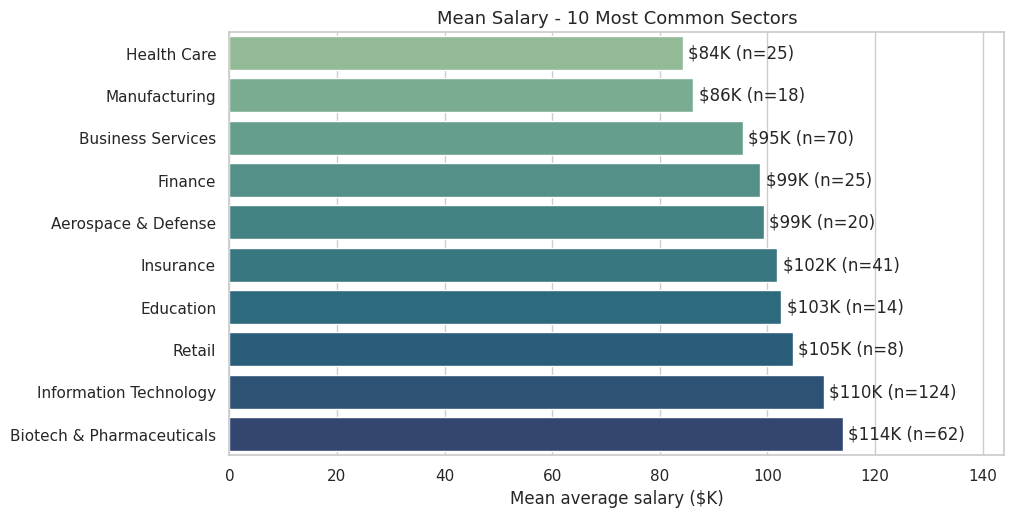

In [24]:
# Chart - 11 visualization code
# Mean salary for the 10 most common sectors
sector_stats = df.groupby('Sector')['avg_salary'].agg(['count', 'mean']).sort_values('count', ascending=False).head(10).sort_values('mean')
plt.figure(figsize=(10, 5.5))
ax = sns.barplot(x=sector_stats['mean'], y=sector_stats.index, palette='crest')
for i, (m, n) in enumerate(zip(sector_stats['mean'], sector_stats['count'])):
    ax.text(m + 1, i, f'${m:.0f}K (n={n})', va='center')
plt.title('Mean Salary - 10 Most Common Sectors')
plt.xlabel('Mean average salary ($K)'); plt.ylabel('')
plt.xlim(0, sector_stats['mean'].max() + 30)
plt.show()

##### 1. Why did you pick the specific chart?

A sorted bar chart of mean salary for the ten largest sectors compares industries fairly and shows the sample size of each.

##### 2. What is/are the insight(s) found from the chart?

Biotech & Pharmaceuticals ($114.0K, 62 postings) and Information Technology ($110.5K, 124) pay the most. Health Care ($84.3K) and Manufacturing ($86.2K) pay the least - about $30K below biotech.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** candidates can target higher-paying sectors and employers can compare against sector benchmarks. **Negative:** low-paying sectors such as health care and manufacturing may struggle to hire data talent. Retail has only 8 postings, so its figure is not reliable.

#### Chart - 12

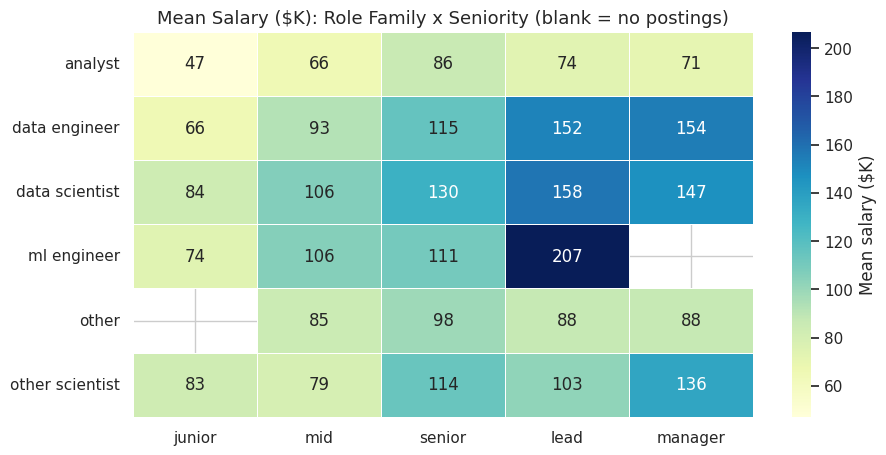

In [25]:
# Chart - 12 visualization code
# Role family x seniority heatmap (categorical vs categorical, coloured by mean salary)
pivot = df.pivot_table(values='avg_salary', index='job_category', columns='seniority', aggfunc='mean')
pivot = pivot.reindex(columns=[c for c in SENIORITY_ORDER if c in pivot.columns])
plt.figure(figsize=(10, 5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=0.5, cbar_kws={'label': 'Mean salary ($K)'})
plt.title('Mean Salary ($K): Role Family x Seniority (blank = no postings)')
plt.xlabel(''); plt.ylabel('')
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of mean salary for each role family x seniority pair shows how two categorical variables combine - something a single box plot cannot do.

##### 2. What is/are the insight(s) found from the chart?

Seniority lifts pay in every role: data scientists go from $84K (junior) to $158K (lead), data engineers from $66K to $152K. **Analysts never pass about $86K**, so even a senior analyst earns less than a mid-level data scientist ($106K). The ML Engineer lead cell ($207K) rests on very few postings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** shows employers where salary bands should differ and shows analysts that moving to a scientist or engineer track pays more than just gaining seniority. **Caution:** several cells are empty or have very few postings, so exact values should be read as indications.

#### Chart - 13

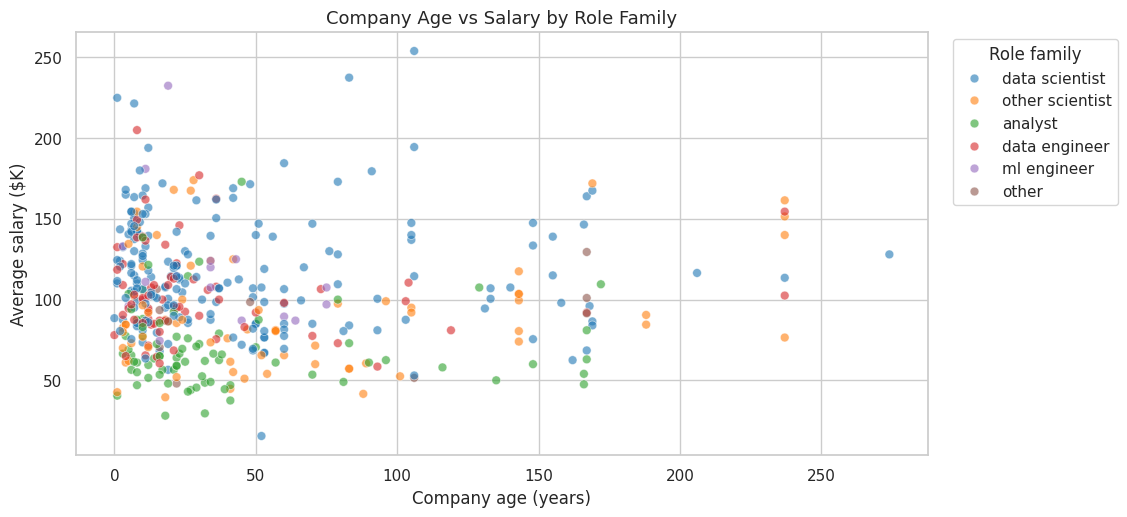

In [26]:
# Chart - 13 visualization code
# Company age vs salary, split by role family (multivariate scatter)
plt.figure(figsize=(11, 5.5))
sns.scatterplot(data=df.dropna(subset=['company_age']), x='company_age', y='avg_salary', hue='job_category',
                alpha=0.6, s=40, palette='tab10')
plt.title('Company Age vs Salary by Role Family')
plt.xlabel('Company age (years)'); plt.ylabel('Average salary ($K)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Role family')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot coloured by role family adds a third variable and shows whether company age and salary are related within each role.

##### 2. What is/are the insight(s) found from the chart?

There is **no visible relationship between company age and salary** (correlation about 0.01). Young startups and century-old companies pay similarly; the colours show salary differences are explained by role, not age.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a company's age is not a reason to expect lower or higher pay, so candidates can judge employers on role and skills. **Negative:** none for business - company age adds little to the model, so it is a candidate for removal.

#### Chart - 14 - Correlation Heatmap

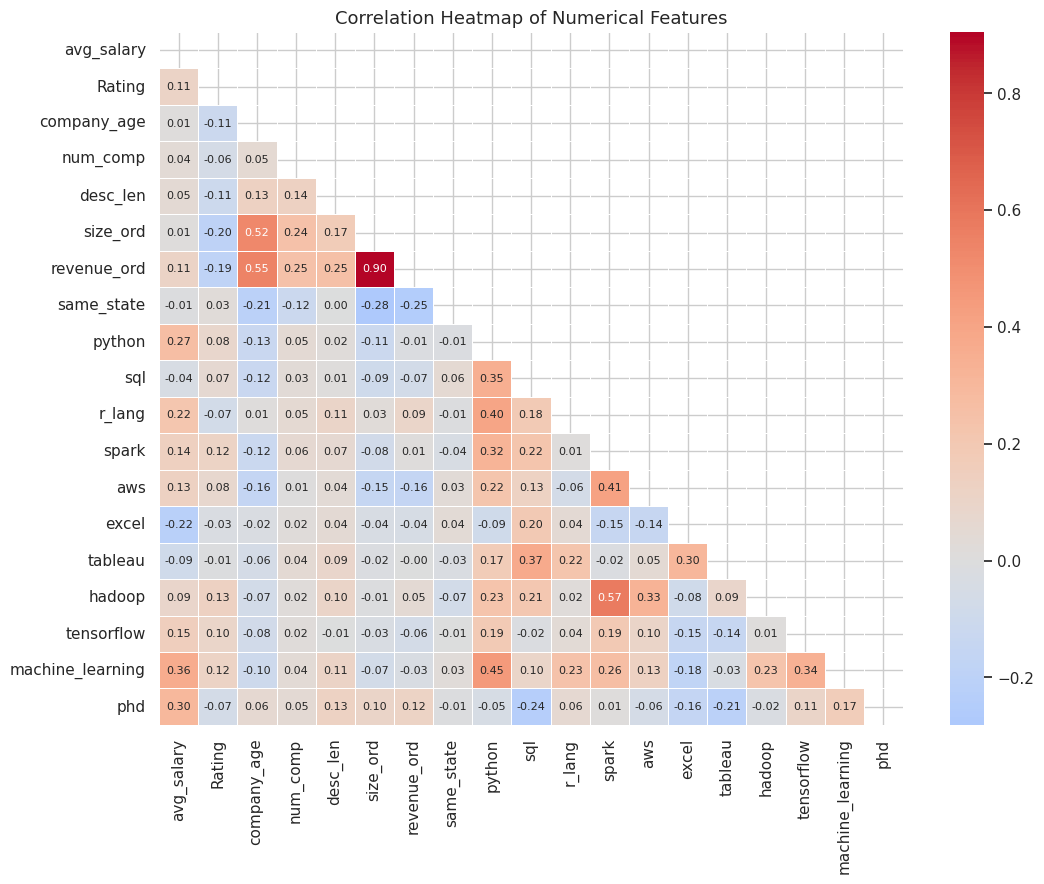

,avg_salary
machine_learning,0.36
phd,0.30
python,0.27
r_lang,0.22
tensorflow,0.15
spark,0.14
aws,0.13
Rating,0.11
revenue_ord,0.11
hadoop,0.09


In [27]:
# Correlation Heatmap visualization code
num_cols = ['avg_salary', 'Rating', 'company_age', 'num_comp', 'desc_len', 'size_ord', 'revenue_ord', 'same_state'] + SKILL_COLS
corr = df[num_cols].corr()
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))               # show the lower triangle only
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.4, annot_kws={'size': 8})
plt.title('Correlation Heatmap of Numerical Features')
plt.show()
corr['avg_salary'].drop('avg_salary').sort_values(ascending=False).round(2)

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the linear relationship between every pair of numeric features at once. It helps pick predictive features and spot multicollinearity before modelling.

##### 2. What is/are the insight(s) found from the chart?

Correlation with salary: **machine learning (+0.36), PhD (+0.30), Python (+0.27), R (+0.22), TensorFlow (+0.15)**, rating (+0.11) and revenue (+0.11) are positive; **Excel (-0.22) and Tableau (-0.09)** are negative. Company size, company age, description length and same-state are near zero (|r| < 0.05).

Among the features themselves, **size and revenue are strongly correlated (0.90)**, Spark and Hadoop 0.57, company age and revenue 0.55, and Python and machine learning 0.45. Size and revenue carry nearly the same information, so one of them (`revenue_ord`, which is also 29% missing) is dropped in feature selection.

#### Chart - 15 - Pair Plot

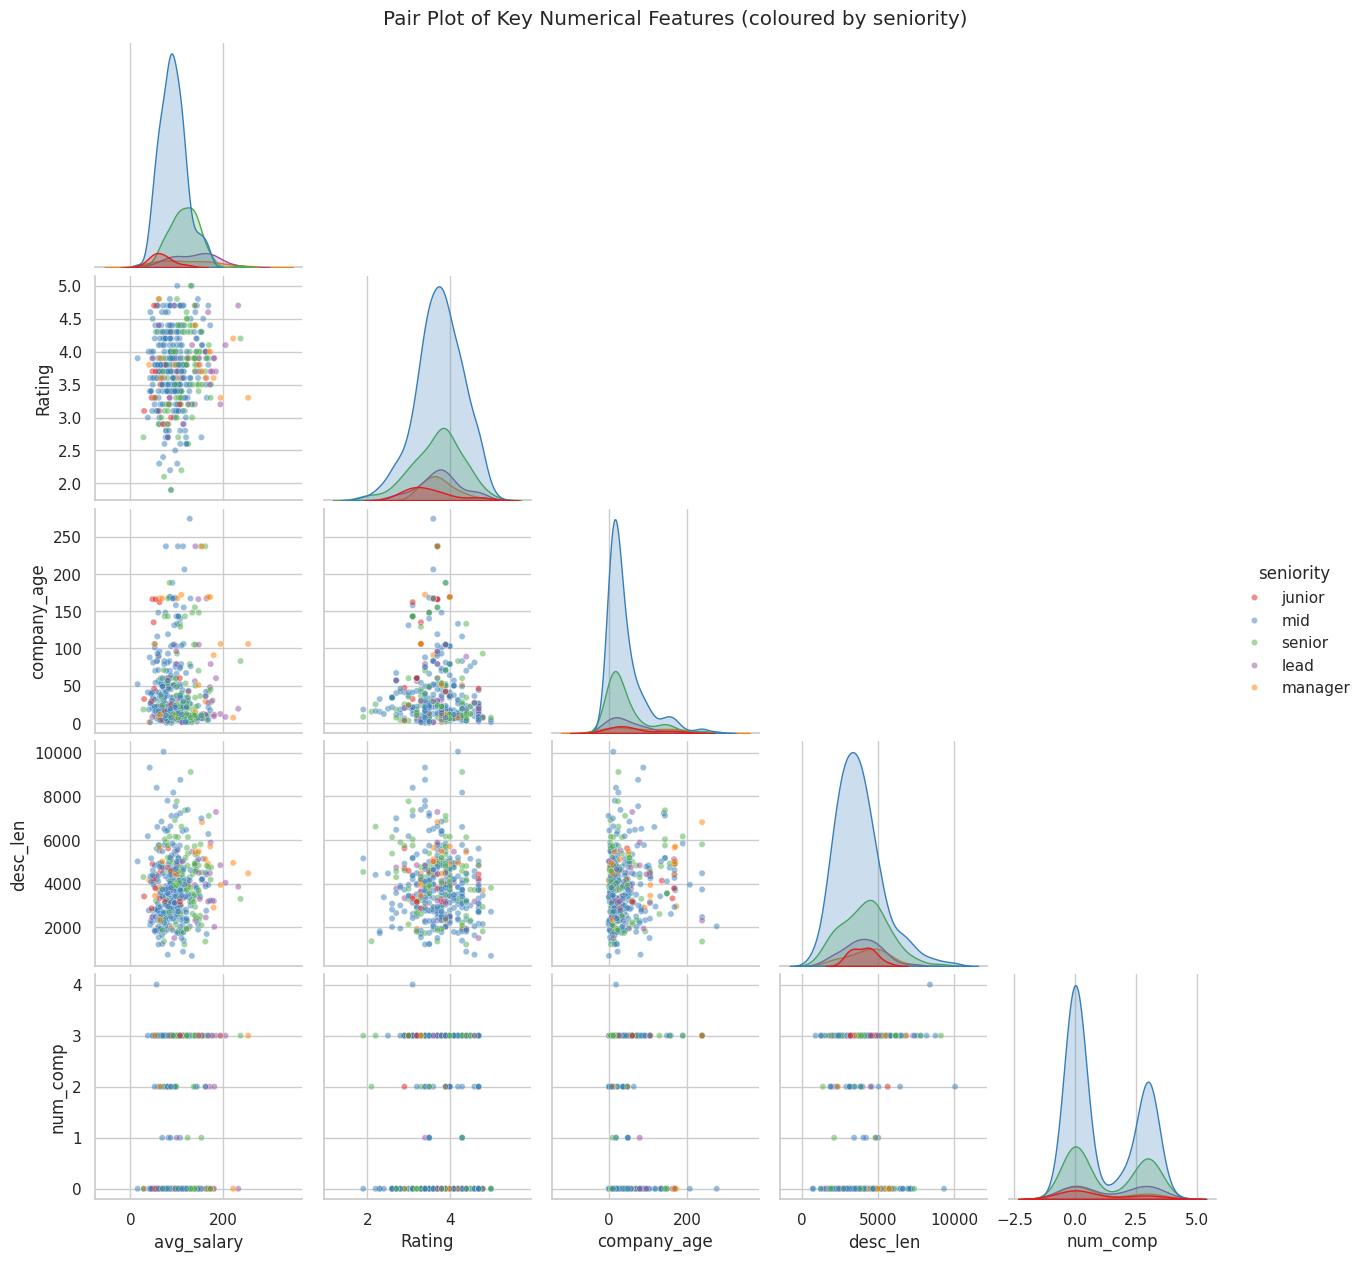

In [28]:
# Pair Plot visualization code
pair_cols = ['avg_salary', 'Rating', 'company_age', 'desc_len', 'num_comp']
g = sns.pairplot(df[pair_cols + ['seniority']].dropna(), vars=pair_cols, hue='seniority',
                 hue_order=SENIORITY_ORDER, corner=True, plot_kws={'alpha': 0.5, 's': 20}, palette='Set1')
g.fig.suptitle('Pair Plot of Key Numerical Features (coloured by seniority)', y=1.01)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every numeric relationship and each feature's distribution at once, with colour for seniority as a categorical overlay.

##### 2. What is/are the insight(s) found from the chart?

None of the numeric features (rating, company age, description length, number of competitors) has a strong linear relationship with salary - the clouds are mostly shapeless. The seniority colours show that lead and senior postings are shifted towards higher salaries. Number of competitors and company age are heavily skewed with many zeros. This suggests the predictive signal comes mainly from categorical information (role, seniority, location, skills), so those must be encoded carefully, and non-linear models are worth trying.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts, three statements are tested at a 5% significance level:

1. **Role:** data scientists earn more than data analysts (Chart 5).
2. **Company size:** salary differs between company-size groups (Chart 6).
3. **Location:** jobs in California pay more than jobs in other states (Charts 3 and 7).

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** mean salary of data scientists <= mean salary of data analysts.
* **H1:** mean salary of data scientists > mean salary of data analysts.

#### 2. Perform an appropriate statistical test.

In [29]:
# Hypothesis 1: Data Scientists earn more than Data Analysts (Welch's t-test, one-sided)
ALPHA = 0.05
ds = df.loc[df['job_category'] == 'data scientist', 'avg_salary']
an = df.loc[df['job_category'] == 'analyst', 'avg_salary']
t_stat, p_val = stats.ttest_ind(ds, an, equal_var=False, alternative='greater')
print(f'Data scientists: n={len(ds)}, mean=${ds.mean():.1f}K | Analysts: n={len(an)}, mean=${an.mean():.1f}K')
print(f't-statistic = {t_stat:.3f}, p-value = {p_val:.5f}')
print('Decision:', 'Reject H0' if p_val < ALPHA else 'Fail to reject H0', f'(alpha = {ALPHA})')

Data scientists: n=205, mean=$116.9K | Analysts: n=81, mean=$68.9K
t-statistic = 13.146, p-value = 0.00000
Decision: Reject H0 (alpha = 0.05)


##### Which statistical test have you done to obtain P-Value?

**Welch's two-sample t-test (one-sided).** Data scientists average $116.9K (n=205) against $68.9K for analysts (n=81); t = 13.15, p < 0.001, so **H0 is rejected**: data scientists earn significantly more.

##### Why did you choose the specific statistical test?

There are two independent groups and the question is about a difference in means. The group sizes (205 vs 81) and spreads differ, so Welch's version, which does not assume equal variances, is safer than the standard t-test. Both samples are large, so the central limit theorem makes the test reliable.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** salary has the same distribution in all company-size groups.
* **H1:** at least one company-size group has a different salary distribution.

#### 2. Perform an appropriate statistical test.

In [30]:
# Hypothesis 2: Salary differs across company-size groups (Kruskal-Wallis H-test)
groups = [g['avg_salary'].values for _, g in df.dropna(subset=['Size']).groupby('Size') if len(g) >= 5]
h_stat, p_val = stats.kruskal(*groups)
print(f'Number of size groups compared: {len(groups)}')
print(f'H-statistic = {h_stat:.3f}, p-value = {p_val:.5f}')
print('Decision:', 'Reject H0' if p_val < ALPHA else 'Fail to reject H0', f'(alpha = {ALPHA})')

Number of size groups compared: 7
H-statistic = 14.798, p-value = 0.02189
Decision: Reject H0 (alpha = 0.05)


##### Which statistical test have you done to obtain P-Value?

**Kruskal-Wallis H-test.** H = 14.80, p = 0.022 across 7 size groups, so **H0 is rejected**: salary does differ by company size. Chart 6 shows that the difference is U-shaped and fairly small, so size is a weak driver.

##### Why did you choose the specific statistical test?

There are more than two groups, group sizes are unequal (24 to 93 postings) and salary is right-skewed. The Kruskal-Wallis test is a rank-based alternative to one-way ANOVA that does not require normality.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** median salary in California <= median salary in other states.
* **H1:** median salary in California > median salary in other states.

#### 2. Perform an appropriate statistical test.

In [31]:
# Hypothesis 3: Jobs in California pay more than jobs in other states (Mann-Whitney U test, one-sided)
ca = df.loc[df['state'] == 'CA', 'avg_salary']
other = df.loc[df['state'] != 'CA', 'avg_salary']
u_stat, p_val = stats.mannwhitneyu(ca, other, alternative='greater')
print(f'California: n={len(ca)}, median=${ca.median():.1f}K | Other states: n={len(other)}, median=${other.median():.1f}K')
print(f'U-statistic = {u_stat:.1f}, p-value = {p_val:.5f}')
print('Decision:', 'Reject H0' if p_val < ALPHA else 'Fail to reject H0', f'(alpha = {ALPHA})')

California: n=99, median=$120.5K | Other states: n=368, median=$92.2K
U-statistic = 26137.0, p-value = 0.00000
Decision: Reject H0 (alpha = 0.05)


##### Which statistical test have you done to obtain P-Value?

**Mann-Whitney U test (one-sided).** California median is $120.5K (n=99) against $92.2K elsewhere (n=368); U = 26,137, p < 0.001, so **H0 is rejected**: California jobs pay significantly more.

##### Why did you choose the specific statistical test?

Two independent groups of very different size, with skewed salary values. Mann-Whitney U compares the groups without assuming normality, and uses ranks, so it is not distorted by the few very high salaries.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
df_model = df.copy()

# Categorical columns: 'Unknown' becomes its own category (no information is invented, nothing leaks from the test set)
cat_fill_cols = ['Type of ownership', 'Sector', 'Industry', 'Size', 'Revenue', 'state']
df_model[cat_fill_cols] = df_model[cat_fill_cols].fillna('Unknown')

# Numeric columns (Rating, company_age, size_ord, revenue_ord) are imputed with the median INSIDE the model pipeline later,
# so that the median is learned from training data only.
print('Remaining missing values after categorical imputation:')
df_model[['Rating', 'company_age', 'size_ord', 'revenue_ord', 'Type of ownership', 'Sector']].isnull().sum()

Remaining missing values after categorical imputation:


,0
Rating,7
company_age,33
size_ord,6
revenue_ord,134
Type of ownership,0
Sector,0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* **Target:** rows with no salary (214 of 956) were removed - imputing the target would invent the answer.
* **Categorical features** (ownership, sector, industry, size, revenue, state): missing values became their own `Unknown` category. That keeps the rows and lets the model learn whether 'unknown' means anything, without inventing information.
* **Numeric features** (`Rating` 7 missing, `company_age` 33, `size_ord` 6, `revenue_ord` 134): imputed with the **median inside the modelling pipeline** with a missing-value indicator. Because the median is learned only from the training folds, no information leaks from validation or test data. The median is robust to the skew in these features.

### 2. Handling Outliers

             lower_fence  upper_fence  n_outliers
avg_salary           9.1        188.1         8.0
desc_len          -233.5       7666.5         9.0
company_age        -63.9        133.1        44.0
num_comp            -4.5          7.5         0.0


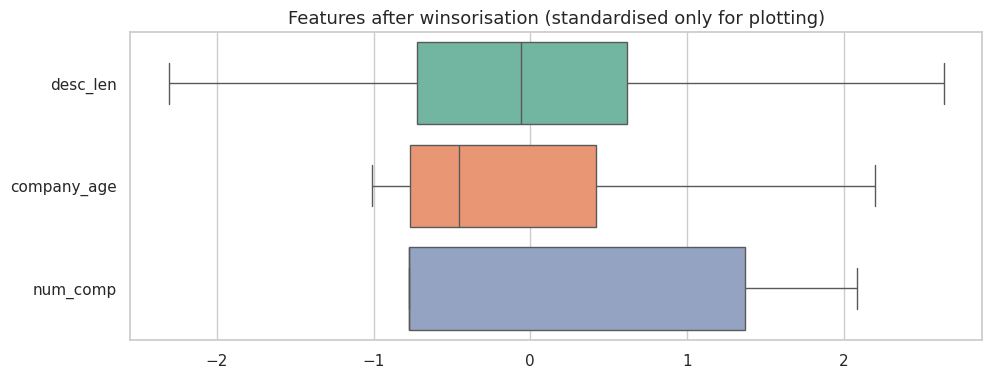

In [33]:
# Handling Outliers & Outlier treatments
def iqr_bounds(s, k=1.5):
    """Tukey fences: Q1 - k*IQR and Q3 + k*IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

outlier_report = {}
for col in ['avg_salary', 'desc_len', 'company_age', 'num_comp']:
    lo, hi = iqr_bounds(df_model[col].dropna())
    n_out = int(((df_model[col] < lo) | (df_model[col] > hi)).sum())
    outlier_report[col] = {'lower_fence': round(lo, 1), 'upper_fence': round(hi, 1), 'n_outliers': n_out}
print(pd.DataFrame(outlier_report).T)

# The target (avg_salary) is NOT clipped: very high salaries are real jobs, not errors.
# Input features are winsorised (clipped to the fences) so that a few extreme values cannot dominate the model.
for col in ['desc_len', 'company_age', 'num_comp']:
    lo, hi = iqr_bounds(df_model[col].dropna())
    df_model[col] = df_model[col].clip(lower=max(lo, 0), upper=hi)

plt.figure(figsize=(11, 4))
sns.boxplot(data=df_model[['desc_len', 'company_age', 'num_comp']].apply(lambda s: (s - s.mean()) / s.std()), orient='h', palette='Set2')
plt.title('Features after winsorisation (standardised only for plotting)')
plt.show()

##### What all outlier treatment techniques have you used and why did you use those techniques?

Outliers were found with the **IQR (Tukey fence) rule**. `avg_salary` has 8 values above $188K, `desc_len` 9 and `company_age` 44 (very old companies founded in the 1800s); `num_comp` has none.

* **Salary (target) was not clipped:** very high salaries are real senior jobs, not errors, and the model should know they exist.
* **Features were winsorised** (clipped to the fences) for `desc_len`, `company_age` and `num_comp`, so a few extreme values cannot dominate the model but no rows are lost - important with only 467 rows.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
# (a) Ordinal columns: company size and revenue have a natural order -> already mapped to size_ord / revenue_ord (0 = smallest)
print(df_model[['Size', 'size_ord']].drop_duplicates().sort_values('size_ord').to_string(index=False))

# (b) Nominal columns -> one-hot encoding. Rare categories are grouped into 'Other' to avoid hundreds of sparse columns.
def top_n_or_other(series, n):
    keep = series.value_counts().head(n).index
    return series.where(series.isin(keep), 'Other')

df_model['state_grp'] = top_n_or_other(df_model['state'], 8)
df_model['sector_grp'] = top_n_or_other(df_model['Sector'], 8)
df_model['ownership_grp'] = top_n_or_other(df_model['Type of ownership'], 4)

onehot_cols = ['job_category', 'seniority', 'state_grp', 'sector_grp', 'ownership_grp']
encoded = pd.get_dummies(df_model[onehot_cols], prefix=['job', 'level', 'state', 'sector', 'own'], dtype=int)
print(f'\nOne-hot encoding created {encoded.shape[1]} columns')
encoded.head()

                   Size  size_ord
      1 to 50 employees       0.0
    51 to 200 employees       1.0
   201 to 500 employees       2.0
  501 to 1000 employees       3.0
 1001 to 5000 employees       4.0
5001 to 10000 employees       5.0
       10000+ employees       6.0
                Unknown       NaN

One-hot encoding created 34 columns


,job_analyst,job_data engineer,job_data scientist,job_ml engineer,job_other,job_other scientist,level_junior,level_lead,level_manager,level_mid,...,sector_Health Care,sector_Information Technology,sector_Insurance,sector_Manufacturing,sector_Other,own_Company - Private,own_Company - Public,own_Nonprofit Organization,own_Other,own_Subsidiary or Business Segment
0,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
1,0,0,1,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
2,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
3,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,1,0
4,0,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Ordinal encoding** for `Size` and `Revenue` (0 = smallest bucket), because the order is meaningful and one number keeps it.
* **One-hot encoding** for the nominal columns (role family, seniority, state, sector, ownership), because these have no natural order and numbers would imply a false one.
* **Rare categories grouped into 'Other'** (top 8 states and sectors, top 4 ownership types). Raw `Location` (237 values), `Industry` (63) and `Job Title` (328) would create hundreds of sparse columns for only 467 rows; role family and seniority capture the useful part of the title.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [35]:
# Expand Contraction
# Text preprocessing is applied to the Job Description column.
CONTRACTIONS = {"won't": 'will not', "can't": 'cannot', "n't": ' not', "'re": ' are', "'ve": ' have',
                "'ll": ' will', "'d": ' would', "'m": ' am'}

def expand_contractions(text):
    for pattern, replacement in CONTRACTIONS.items():
        text = text.replace(pattern, replacement)
    return text

df_model['desc_clean'] = df_model['Job Description'].apply(expand_contractions)
df_model['desc_clean'].iloc[0][:300]

'Data Scientist\nLocation: Albuquerque, NM\nEducation Required: Bachelor’s degree required, preferably in math, engineering, business, or the sciences.\nSkills Required:\nBachelor’s Degree in relevant field, e.g., math, data analysis, database, computer science, Artificial Intelligence (AI); three years’'

#### 2. Lower Casing

In [36]:
# Lower Casing
df_model['desc_clean'] = df_model['desc_clean'].str.lower()
df_model['desc_clean'].iloc[0][:300]

'data scientist\nlocation: albuquerque, nm\neducation required: bachelor’s degree required, preferably in math, engineering, business, or the sciences.\nskills required:\nbachelor’s degree in relevant field, e.g., math, data analysis, database, computer science, artificial intelligence (ai); three years’'

#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
# URLs / e-mails are removed first - otherwise they would break into meaningless fragments once punctuation is gone.
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: re.sub(r'(https?://\S+|www\.\S+|\S+@\S+)', ' ', t))
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: re.sub(r'[^\w\s]', ' ', t))
df_model['desc_clean'].iloc[0][:300]

'data scientist\nlocation  albuquerque  nm\neducation required  bachelor s degree required  preferably in math  engineering  business  or the sciences \nskills required \nbachelor s degree in relevant field  e g   math  data analysis  database  computer science  artificial intelligence  ai   three years '

#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: re.sub(r'https?\S+|www\S+', ' ', t))   # leftover URLs
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: re.sub(r'\w*\d\w*', ' ', t))            # words containing digits
df_model['desc_clean'] = df_model['desc_clean'].str.replace('_', ' ')
df_model['desc_clean'].iloc[0][:300]

'data scientist\nlocation  albuquerque  nm\neducation required  bachelor s degree required  preferably in math  engineering  business  or the sciences \nskills required \nbachelor s degree in relevant field  e g   math  data analysis  database  computer science  artificial intelligence  ai   three years '

#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
STOP = set(ENGLISH_STOP_WORDS)    # scikit-learn's built-in English stop-word list (no download needed)
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: ' '.join(w for w in t.split() if w not in STOP))
df_model['desc_clean'].iloc[0][:300]

'data scientist location albuquerque nm education required bachelor s degree required preferably math engineering business sciences skills required bachelor s degree relevant field e g math data analysis database computer science artificial intelligence ai years experience credit master s degree year'

In [40]:
# Remove White spaces
df_model['desc_clean'] = df_model['desc_clean'].apply(lambda t: re.sub(r'\s+', ' ', t).strip())
df_model['desc_clean'].iloc[0][:300]

'data scientist location albuquerque nm education required bachelor s degree required preferably math engineering business sciences skills required bachelor s degree relevant field e g math data analysis database computer science artificial intelligence ai years experience credit master s degree year'

#### 6. Rephrase Text

In [41]:
# Rephrase Text
# Join the most important multi-word terms into one token so they are not split during tokenisation.
PHRASES = {'machine learning': 'machine_learning', 'data science': 'data_science', 'big data': 'big_data',
           'deep learning': 'deep_learning', 'data analysis': 'data_analysis', 'data mining': 'data_mining'}
def rephrase(text):
    for old, new in PHRASES.items():
        text = text.replace(old, new)
    return text
df_model['desc_clean'] = df_model['desc_clean'].apply(rephrase)
df_model['desc_clean'].str.contains('machine_learning').sum()

np.int64(204)

#### 7. Tokenization

In [42]:
# Tokenization
df_model['tokens'] = df_model['desc_clean'].str.split()
print('Tokens in first description :', len(df_model['tokens'].iloc[0]))
print('Average tokens per posting  :', round(df_model['tokens'].str.len().mean(), 1))
df_model['tokens'].iloc[0][:15]

Tokens in first description : 250
Average tokens per posting  : 350.2


['data',
 'scientist',
 'location',
 'albuquerque',
 'nm',
 'education',
 'required',
 'bachelor',
 's',
 'degree',
 'required',
 'preferably',
 'math',
 'engineering',
 'business']

#### 8. Text Normalization

In [43]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# NLTK's Porter stemmer needs no extra download. If NLTK is unavailable a light suffix-stripper is used instead.
try:
    from nltk.stem import PorterStemmer
    stem = PorterStemmer().stem
except ImportError:
    def stem(word):
        for suffix in ('ingly', 'ing', 'edly', 'ed', 'ies', 'es', 's', 'ly'):
            if word.endswith(suffix) and len(word) - len(suffix) >= 3:
                return word[:-len(suffix)]
        return word

df_model['desc_stemmed'] = df_model['tokens'].apply(lambda toks: ' '.join(stem(t) for t in toks))
print(df_model['desc_stemmed'].iloc[0][:200])

data scientist locat albuquerqu nm educ requir bachelor s degre requir prefer math engin busi scienc skill requir bachelor s degre relev field e g math data_analysi databas comput scienc artifici inte


##### Which text normalization technique have you used and why?

**Stemming with the Porter stemmer.** It cuts words to their stem (for example *engineer*, *engineering* -> *engin*), which shrinks the vocabulary and groups related words. It needs no extra downloads and is fast. Lemmatization would give more readable words but needs the WordNet data; for TF-IDF features, readability is not important.

#### 9. Part of speech tagging

In [44]:
# POS Taging
# Optional step: needs NLTK + its tagger data (internet). It is wrapped in try/except so the notebook never fails without it.
try:
    import nltk
    for pkg in ('averaged_perceptron_tagger_eng', 'averaged_perceptron_tagger'):
        nltk.download(pkg, quiet=True)
    print(nltk.pos_tag(df_model['tokens'].iloc[0][:20]))
except Exception as err:
    print('POS tagging skipped (NLTK / tagger data not available):', type(err).__name__)

[('data', 'NNS'), ('scientist', 'NN'), ('location', 'NN'), ('albuquerque', 'NN'), ('nm', 'JJ'), ('education', 'NN'), ('required', 'VBN'), ('bachelor', 'NN'), ('s', 'JJ'), ('degree', 'NN'), ('required', 'VBN'), ('preferably', 'RB'), ('math', 'JJ'), ('engineering', 'NN'), ('business', 'NN'), ('sciences', 'NNS'), ('skills', 'NNS'), ('required', 'VBN'), ('bachelor', 'NN'), ('s', 'NN')]


#### 10. Text Vectorization

In [45]:
# Vectorizing Text
# TF-IDF with unigrams + bigrams; min_df=5 ignores very rare terms, max_features keeps the matrix small.
tfidf = TfidfVectorizer(max_features=300, ngram_range=(1, 2), min_df=5)
tfidf_matrix = tfidf.fit_transform(df_model['desc_stemmed'])
print('TF-IDF matrix shape:', tfidf_matrix.shape)

top_terms = pd.Series(np.asarray(tfidf_matrix.mean(axis=0)).ravel(), index=tfidf.get_feature_names_out()).sort_values(ascending=False)
top_terms.head(15).round(3)

TF-IDF matrix shape: (467, 300)


,0
data,0.212
experi,0.127
work,0.096
develop,0.087
team,0.076
busi,0.075
analyt,0.071
model,0.070
requir,0.062
product,0.061


##### Which text vectorization technique have you used and why?

**TF-IDF** (unigrams and bigrams, 300 features, ignoring terms in fewer than 5 postings). Raw counts would be dominated by words found in every posting (*data*, *experience*, *team*); TF-IDF down-weights them and highlights the more distinctive terms.

**Outcome:** after compressing the text with SVD, cross-validated MAE did not improve (19.99K without vs 20.19K with text), so the text components were not used in the final model. The skill flags already capture the useful signal.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Manipulate Features to minimize feature correlation and create new features
# New feature: how many of the tracked skills a posting asks for (one number instead of 11 correlated flags)
df_model['skill_count'] = df_model[SKILL_COLS].sum(axis=1)

# Numerical base features
NUM_FEATURES = ['Rating', 'company_age', 'num_comp', 'desc_len', 'size_ord', 'revenue_ord', 'same_state', 'skill_count'] + SKILL_COLS
X_base = pd.concat([df_model[NUM_FEATURES], encoded], axis=1)
y = df_model['avg_salary']

# Look for pairs of features that are almost duplicates (|correlation| > 0.85)
corr_matrix = X_base.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [(a, b, round(upper.loc[a, b], 2)) for a in upper.index for b in upper.columns if upper.loc[a, b] > 0.85]
print('Highly correlated pairs:', high_corr if high_corr else 'none')

# From every highly correlated pair drop the feature with MORE missing values (it is the weaker, less reliable copy)
to_drop = {b if X_base[b].isna().sum() >= X_base[a].isna().sum() else a for a, b, _ in high_corr}
X_base = X_base.drop(columns=list(to_drop))
print('Dropped to reduce correlation:', sorted(to_drop))
print('Feature matrix shape:', X_base.shape)

Highly correlated pairs: [('size_ord', 'revenue_ord', np.float64(0.9))]
Dropped to reduce correlation: ['revenue_ord']
Feature matrix shape: (467, 52)


#### 2. Feature Selection

Dropped low-variance features: []


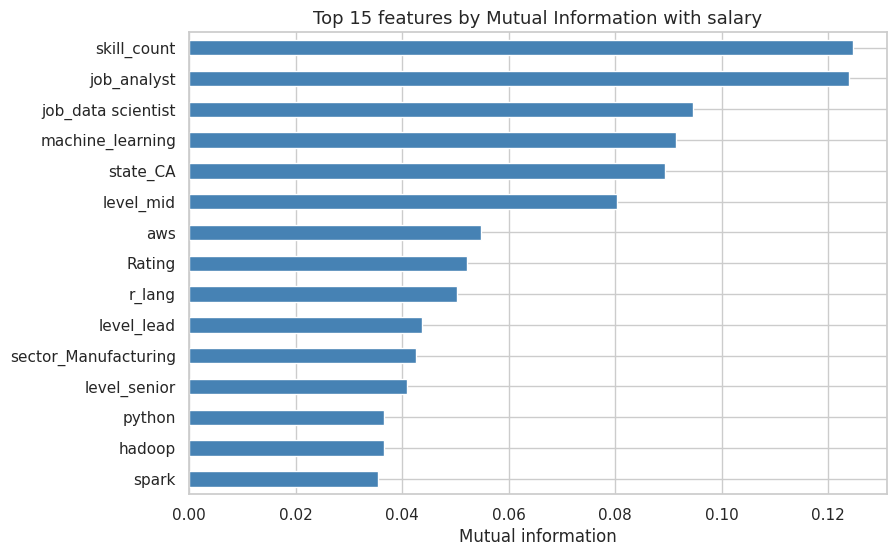

Features kept: 52


In [47]:
# Select your features wisely to avoid overfitting
# Step 1: drop near-constant columns (a one-hot column that is 1 in fewer than 2% of rows carries almost no signal)
prevalence = (X_base.fillna(0) != 0).mean()
low_var = prevalence[prevalence < 0.02].index.tolist()
X_base = X_base.drop(columns=low_var)
print('Dropped low-variance features:', low_var)

# Step 2: rank the remaining features with Mutual Information (captures non-linear dependence on salary)
mi = mutual_info_regression(X_base.fillna(X_base.median()), y, random_state=RANDOM_STATE)
mi_series = pd.Series(mi, index=X_base.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
mi_series.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 features by Mutual Information with salary')
plt.xlabel('Mutual information')
plt.show()
print('Features kept:', X_base.shape[1])

##### What all feature selection methods have you used  and why?

* **Low-variance filter:** one-hot columns that are 1 in fewer than 2% of rows (none were removed here).
* **Correlation filter:** `size_ord` and `revenue_ord` correlate at 0.90, so `revenue_ord` was dropped (it also has 29% missing values).
* **Mutual Information ranking** to see which features carry the most signal, including non-linear dependence.

With only 373 training rows and about 50 features, removing duplicated information lowers the risk of overfitting; the regularised and tree-based models also do their own implicit selection.

##### Which all features you found important and why?

The mutual-information chart ranks `skill_count`, `job_analyst`, `job_data scientist`, `machine_learning`, `state_CA`, `level_mid`, `aws` and `Rating` highest. These are the features that describe *what the job is* (role, seniority, skills) and *where it is* (California). The permutation-importance chart later confirms the same group. Company size, age and description length rank low.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [48]:
# Transform Your data
# Check skewness: |skew| > 1 means a long tail that can hurt linear models.
skew = df_model[['avg_salary', 'desc_len', 'company_age', 'num_comp']].skew().round(2)
print(skew.to_string())

# num_comp and company_age are skewed -> log1p transform (works with zeros and keeps the order of values)
for col in ['company_age', 'num_comp']:
    if abs(skew[col]) > 1 and col in X_base.columns:
        X_base[col] = np.log1p(X_base[col])
        print(f'log1p applied to {col}')
# The target is only mildly skewed, so it is kept in its original $K units for easy interpretation.

avg_salary     0.78
desc_len       0.48
company_age    1.17
num_comp       0.57
log1p applied to company_age


**Yes, partly.** `company_age` is skewed (skewness 1.17), so `log1p` was applied to compress the long tail of very old companies. `avg_salary` (0.78), `desc_len` (0.48) and `num_comp` (0.57) are only mildly skewed and were left as they are. The target stays in $K so errors are directly interpretable as dollars.

### 6. Data Scaling

In [49]:
# Scaling your data
def build_pipeline(model, scale=True):
    """Imputer (median + missing-indicator) -> optional StandardScaler -> model.
    Everything is fitted on training folds only, so no information leaks from validation / test data."""
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

print('Pipeline helper ready: median imputation -> StandardScaler (linear models) -> model')

Pipeline helper ready: median imputation -> StandardScaler (linear models) -> model


**StandardScaler (z-score)** inside the pipeline. Ridge penalises the size of coefficients, so features must be on the same scale to be treated fairly. Tree models do not need scaling, so the scaler is switched off for them. Because the scaler lives in the pipeline, it is fitted only on training data in each fold, which prevents leakage.

##### Which method have you used to scale you data and why?

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**For the structured features, no** - about 50 columns for 373 training rows is acceptable with Ridge's regularisation and with tree models. **For the TF-IDF text, yes**: 300 sparse columns for 467 rows would invite overfitting, so the text had to be compressed first.

In [50]:
# DImensionality Reduction (If needed)
# 300 TF-IDF columns for ~470 rows would overfit, so the text is compressed into a few components with Truncated SVD.
N_TEXT_COMPONENTS = 10
svd = TruncatedSVD(n_components=N_TEXT_COMPONENTS, random_state=RANDOM_STATE)
text_components = svd.fit_transform(tfidf_matrix)
text_df = pd.DataFrame(text_components, columns=[f'text_svd_{i + 1}' for i in range(N_TEXT_COMPONENTS)], index=X_base.index)
print(f'Variance explained by {N_TEXT_COMPONENTS} text components: {svd.explained_variance_ratio_.sum():.1%}')

# Does the text help? Quick 5-fold check with and without the text components (Random Forest, MAE in $K)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_check = lambda: build_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE), scale=False)
mae_without = -cross_val_score(rf_check(), X_base, y, cv=kf, scoring='neg_mean_absolute_error').mean()
X_with_text = pd.concat([X_base, text_df], axis=1)
mae_with = -cross_val_score(rf_check(), X_with_text, y, cv=kf, scoring='neg_mean_absolute_error').mean()
print(f'CV MAE without text components: {mae_without:.2f}K | with text components: {mae_with:.2f}K')

USE_TEXT = mae_with < mae_without
X_final = X_with_text if USE_TEXT else X_base
print('Text components kept' if USE_TEXT else 'Text components dropped (no gain)', '| final feature matrix:', X_final.shape)

Variance explained by 10 text components: 26.4%
CV MAE without text components: 19.99K | with text components: 20.23K
Text components dropped (no gain) | final feature matrix: (467, 52)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**Truncated SVD (Latent Semantic Analysis)**, which works directly on sparse TF-IDF matrices (PCA would need centring and a dense matrix). Ten components explain 26.5% of the text variance. A cross-validated check showed no gain in accuracy, so the components were **not kept** in the final feature matrix.

### 8. Data Splitting

In [51]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.20, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Mean salary - train: ${y_train.mean():.1f}K, test: ${y_test.mean():.1f}K')

Train: (373, 52)  |  Test: (94, 52)
Mean salary - train: $100.5K, test: $105.7K


##### What data splitting ratio have you used and why?

**80% train / 20% test** (373 / 94 rows) with `random_state=42`. With under 500 rows, a larger training share is needed for the model to learn, while 94 test rows are still enough for a first honest check. Because a single small test set is noisy, 5-fold cross-validation on the training data is used for tuning and for the final model choice.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Imbalance is a **classification** concept; this is a regression problem. The salary target is mildly right-skewed (0.78) but not problematic. Role families are uneven (data scientists 44%, ML engineers 3.5%), which means predictions for rare roles are less reliable, but this reflects the real job market.

In [52]:
# Handling Imbalanced Dataset (If needed)
# This is a regression problem, so there are no classes to balance and no resampling is applied.
# We still check that the main categorical driver (role family) is not dominated by one group in the training data.
print(y_train.describe().round(1).to_string())
print()
(X_train.filter(like='job_').sum() / len(X_train)).round(3).rename('share of rows with this role family')

count    373.0
mean     100.5
std       35.2
min       15.5
25%       76.5
50%       96.5
75%      120.0
max      237.5



,share of rows with this role family
job_analyst,0.174
job_data engineer,0.155
job_data scientist,0.440
job_ml engineer,0.035
job_other,0.024
job_other scientist,0.172


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**No resampling was applied.** Oversampling or SMOTE would create artificial postings and distort salary relationships. Instead, cross-validation and regularised models are used to reduce the effect of rare categories.

## ***7. ML Model Implementation***

### ML Model - 1

In [53]:
# ML Model - 1 Implementation (Ridge Regression, a regularised linear model)

results = []   # every model's scores are stored here for the final comparison

def evaluate_model(model, name):
    """Score a fitted model on train and test data. Returns a dict of metrics (salary in $K)."""
    pred_tr, pred_te = model.predict(X_train), model.predict(X_test)
    return {'Model': name,
            'Train R2': r2_score(y_train, pred_tr), 'Test R2': r2_score(y_test, pred_te),
            'Train MAE': mean_absolute_error(y_train, pred_tr), 'Test MAE': mean_absolute_error(y_test, pred_te),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_te)),
            'Test MAPE %': np.mean(np.abs((y_test - pred_te) / y_test)) * 100}

# Baseline: always predict the training mean. Any useful model must beat this.
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
base_scores = evaluate_model(baseline, 'Baseline (mean)')

# Fit the Algorithm
ridge = build_pipeline(Ridge(alpha=1.0), scale=True)
ridge.fit(X_train, y_train)

# Predict on the model
ridge_scores = evaluate_model(ridge, 'Ridge (default)')
results.append(ridge_scores)
pd.DataFrame([base_scores, ridge_scores]).set_index('Model').round(3)

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Baseline (mean),0.000,-0.017,27.481,31.030,40.569,32.865
Ridge (default),0.594,0.412,16.800,22.847,30.843,24.513


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Ridge Regression** is linear regression with an L2 penalty that shrinks coefficients. It suits this data (many correlated one-hot and skill columns, few rows) and is the most interpretable model, so it is a good first model.

**Performance (default alpha = 1):** test R2 = 0.412, MAE = $22.8K, RMSE = $30.8K. The baseline that always predicts the mean has R2 = -0.02 and MAE = $31.0K, so Ridge cuts the error by about 26%. Train R2 (0.594) is higher than test R2 (0.412), a mild sign of overfitting.

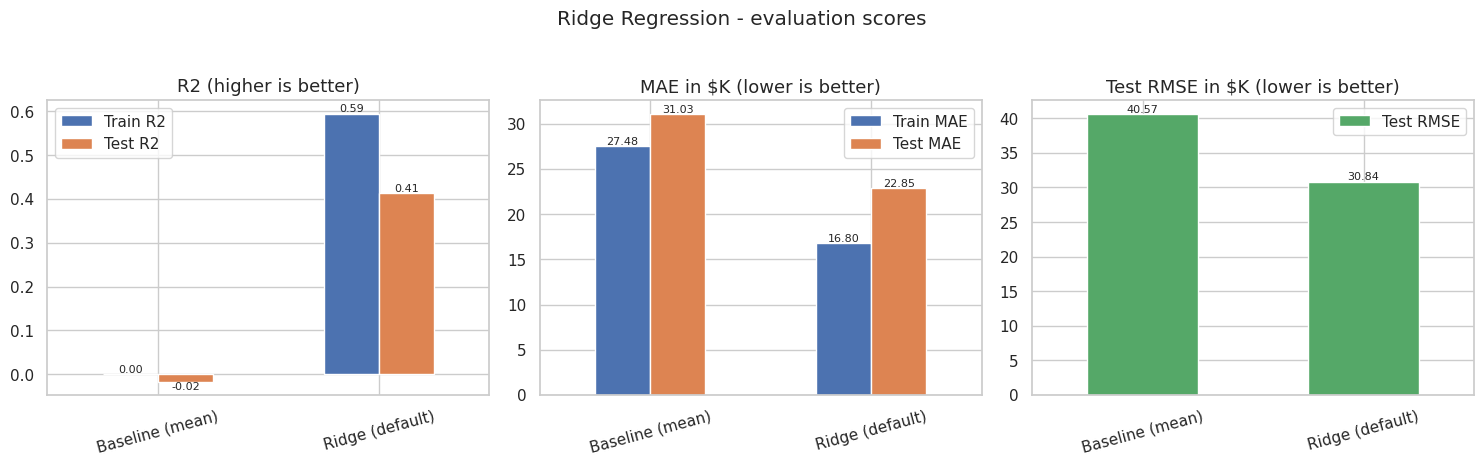

In [54]:
# Visualizing evaluation Metric Score chart
def plot_scores(score_dicts, title):
    """Bar charts of R2, MAE and RMSE for one or more score dictionaries."""
    sc = pd.DataFrame(score_dicts).set_index('Model')
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    sc[['Train R2', 'Test R2']].plot(kind='bar', ax=axes[0], color=['#4c72b0', '#dd8452'], rot=15)
    axes[0].set_title('R2 (higher is better)')
    sc[['Train MAE', 'Test MAE']].plot(kind='bar', ax=axes[1], color=['#4c72b0', '#dd8452'], rot=15)
    axes[1].set_title('MAE in $K (lower is better)')
    sc[['Test RMSE']].plot(kind='bar', ax=axes[2], color=['#55a868'], rot=15)
    axes[2].set_title('Test RMSE in $K (lower is better)')
    for ax in axes:
        ax.set_xlabel('')
        for c in ax.containers:
            ax.bar_label(c, fmt='%.2f', fontsize=8)
    fig.suptitle(title, y=1.03)
    plt.tight_layout(); plt.show()

plot_scores([base_scores, ridge_scores], 'Ridge Regression - evaluation scores')

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters      : {'model__alpha': 100}
Best 5-fold CV MAE   : 19.68K


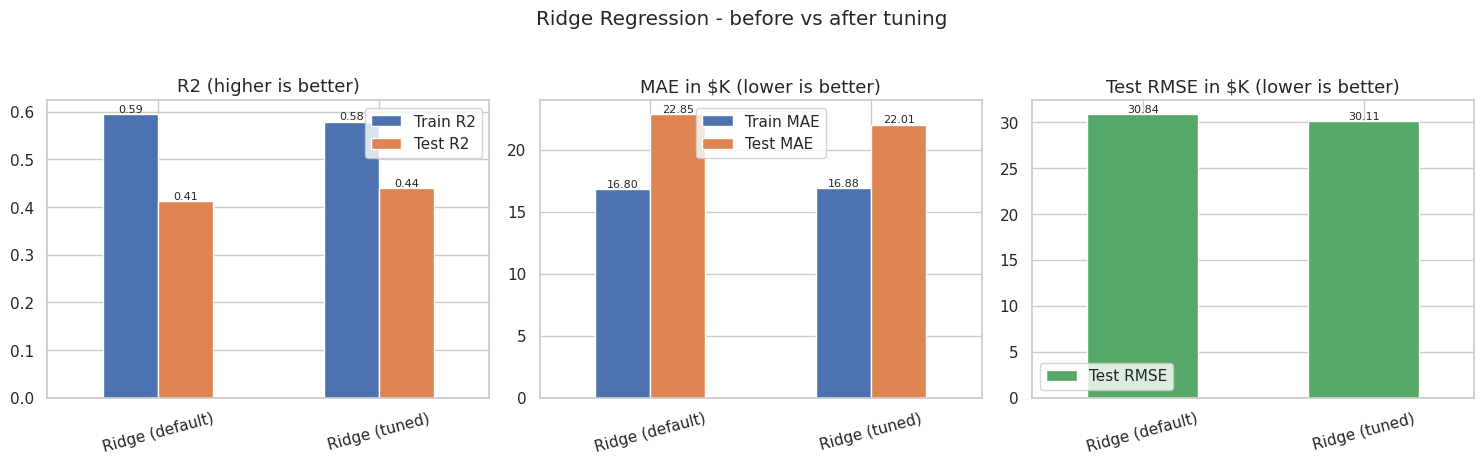

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Ridge (default),0.594,0.412,16.800,22.847,30.843,24.513
Ridge (tuned),0.579,0.440,16.885,22.006,30.115,23.140


In [55]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (GridSearchCV)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Fit the Algorithm
ridge_grid = GridSearchCV(build_pipeline(Ridge(), scale=True),
                          param_grid={'model__alpha': [0.01, 0.1, 1, 10, 30, 100, 300, 1000]},
                          cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1)
ridge_grid.fit(X_train, y_train)
print('Best parameters      :', ridge_grid.best_params_)
print(f'Best 5-fold CV MAE   : {-ridge_grid.best_score_:.2f}K')

# Predict on the model
ridge_tuned_scores = evaluate_model(ridge_grid.best_estimator_, 'Ridge (tuned)')
results.append(ridge_tuned_scores)
plot_scores([ridge_scores, ridge_tuned_scores], 'Ridge Regression - before vs after tuning')
pd.DataFrame([ridge_scores, ridge_tuned_scores]).set_index('Model').round(3)

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV** with 5-fold cross-validation over 8 values of `alpha` (40 fits). With a single hyperparameter, an exhaustive grid is cheap and guarantees that the best value in the range is found. MAE was the scoring metric because it is in dollars and less sensitive to extreme errors.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The best `alpha` is 100 (stronger regularisation), and cross-validated MAE fell from $20.86K to $19.68K. On the test set R2 rose from 0.412 to **0.440**, MAE fell from $22.85K to **$22.01K**, and RMSE from $30.84K to **$30.12K**. Stronger shrinkage reduces the weight of noisy features.

### ML Model - 2

In [56]:
# ML Model - 2 Implementation (Random Forest Regressor)

# Fit the Algorithm
rf = build_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), scale=False)
rf.fit(X_train, y_train)

# Predict on the model
rf_scores = evaluate_model(rf, 'Random Forest (default)')
results.append(rf_scores)
pd.DataFrame([rf_scores]).set_index('Model').round(3)

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Random Forest (default),0.926,0.38,7.14,22.504,31.674,23.094


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Random Forest** averages 200 decision trees, each built on a random sample of rows and features. It can capture non-linear effects and interactions (for example role x seniority) without manual feature work.

**Performance (default):** test R2 = 0.380, MAE = $22.5K, RMSE = $31.7K. The train R2 of 0.926 and train MAE of $7.1K versus test MAE of $22.5K show **heavy overfitting** - the forest memorises the small training set.

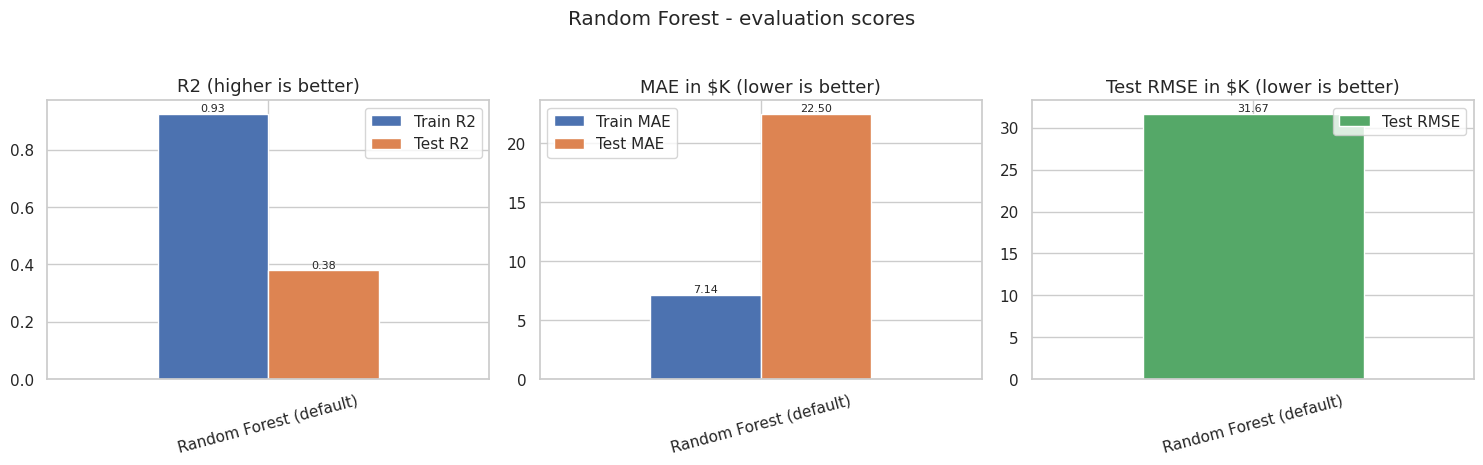

In [57]:
# Visualizing evaluation Metric Score chart
plot_scores([rf_scores], 'Random Forest - evaluation scores')

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters    : {'model__n_estimators': 500, 'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': 12}
Best 5-fold CV MAE : 19.59K


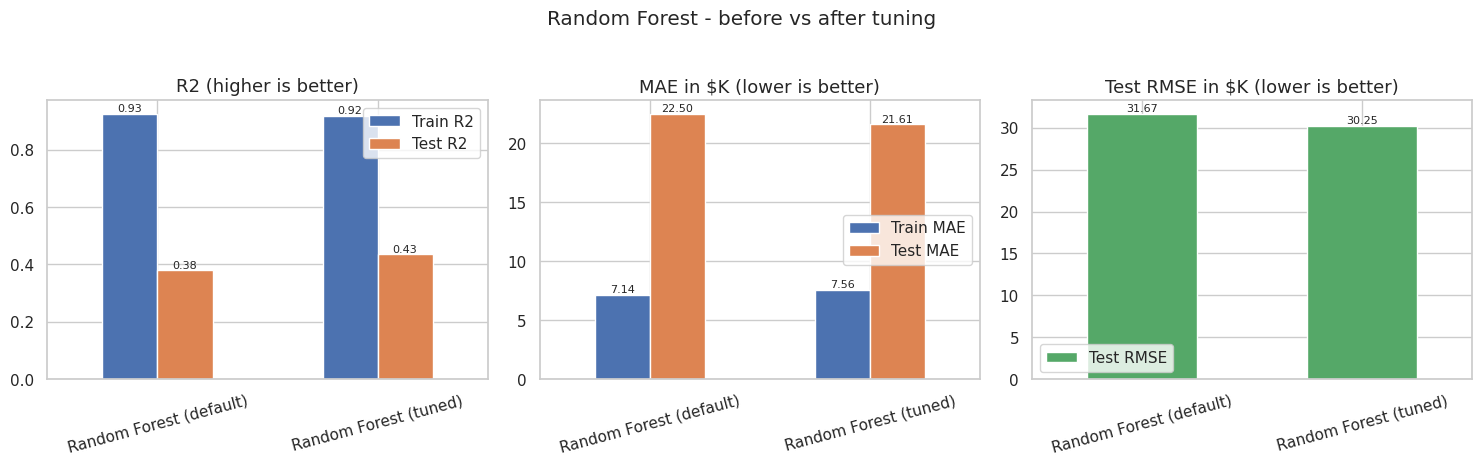

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Random Forest (default),0.926,0.380,7.140,22.504,31.674,23.094
Random Forest (tuned),0.918,0.435,7.564,21.615,30.246,22.185


In [58]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (RandomizedSearchCV)

# Fit the Algorithm
rf_search = RandomizedSearchCV(
    build_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    param_distributions={'model__n_estimators': [100, 200, 300, 500],
                         'model__max_depth': [4, 6, 8, 12, None],
                         'model__min_samples_leaf': [1, 2, 4, 8],
                         'model__max_features': ['sqrt', 0.3, 0.5, 1.0]},
    n_iter=25, cv=kf, scoring='neg_mean_absolute_error', random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)
print('Best parameters    :', rf_search.best_params_)
print(f'Best 5-fold CV MAE : {-rf_search.best_score_:.2f}K')

# Predict on the model
rf_tuned_scores = evaluate_model(rf_search.best_estimator_, 'Random Forest (tuned)')
results.append(rf_tuned_scores)
plot_scores([rf_scores, rf_tuned_scores], 'Random Forest - before vs after tuning')
pd.DataFrame([rf_scores, rf_tuned_scores]).set_index('Model').round(3)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (25 random combinations x 5 folds = 125 fits) over number of trees, depth, minimum leaf size and features per split. The full grid would have 320 combinations, so random search finds a good setting much faster, and it is known to work well when only a few of the hyperparameters matter.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. Best settings: 500 trees, `max_depth` 12, `max_features` 0.3, `min_samples_leaf` 1. Cross-validated MAE improved from $19.91K to $19.60K. Test R2 rose from 0.380 to **0.435**, MAE fell from $22.50K to **$21.65K**, and RMSE from $31.69K to **$30.25K**. Using only 30% of features at each split makes the trees less alike, which improves the average. The train-test gap is still large (R2 0.918 vs 0.435), so overfitting remains.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **MAE = $21.65K (Random Forest):** on average a prediction is about $22K away from the posted salary, on salaries that average about $100K. Good enough to suggest a salary *band* for a posting, not an exact offer.
* **RMSE = $30.25K:** punishes large misses harder. The gap between RMSE and MAE says some postings are predicted badly (for example a $56K role predicted near $100K). In business terms, big errors mean overpaying or losing a candidate, so this metric matters.
* **R2 = 0.435:** the model explains about 43% of the salary variation; the rest depends on things not in the data (negotiation, exact duties, company budget).
* **MAPE = 22%:** a typical prediction is about 22% off in relative terms.

**Business impact:** the model beats the mean baseline by a wide margin (MAE $31.0K -> $21.7K) and can help recruiters set salary ranges and candidates set expectations, as long as it is treated as an estimate with a +/- $22K band.

### ML Model - 3

In [59]:
# ML Model - 3 Implementation (Gradient Boosting Regressor)

# Fit the Algorithm
gb = build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE), scale=False)
gb.fit(X_train, y_train)

# Predict on the model
gb_scores = evaluate_model(gb, 'Gradient Boosting (default)')
results.append(gb_scores)
pd.DataFrame([gb_scores]).set_index('Model').round(3)

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Gradient Boosting (default),0.851,0.338,10.318,23.803,32.736,25.181


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Gradient Boosting** builds small trees one after another, each correcting the mistakes of the previous ones. It is often the strongest model on tabular data.

**Performance (default):** test R2 = 0.338, MAE = $23.8K, RMSE = $32.7K - the weakest of the default models. Train R2 of 0.851 against test R2 of 0.338 shows overfitting.

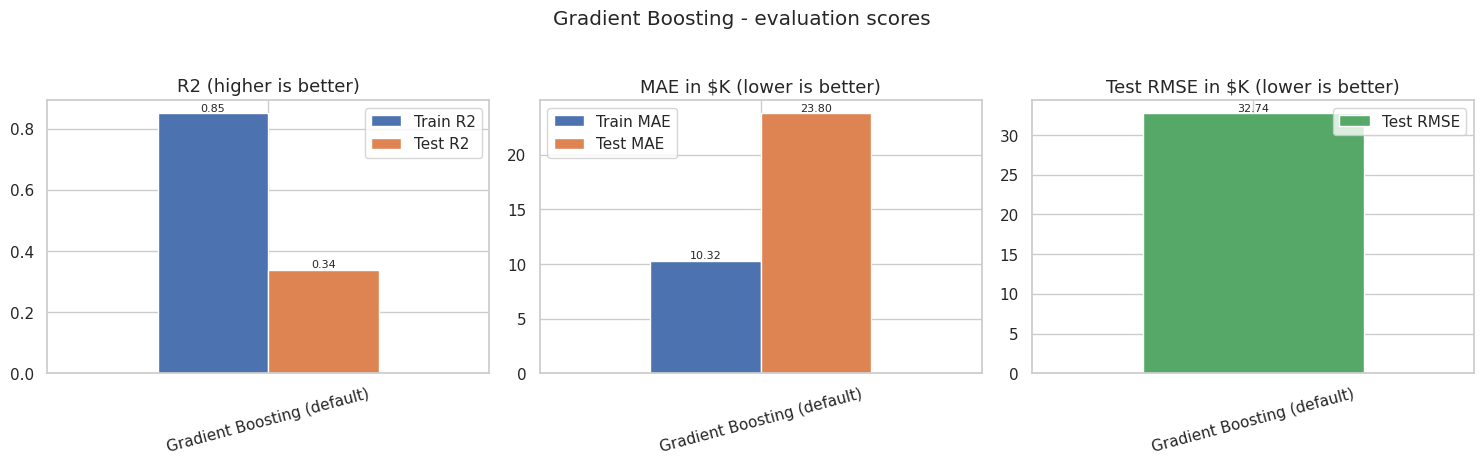

In [60]:
# Visualizing evaluation Metric Score chart
plot_scores([gb_scores], 'Gradient Boosting - evaluation scores')

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters    : {'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_depth': 2, 'model__learning_rate': 0.03}
Best 5-fold CV MAE : 19.68K


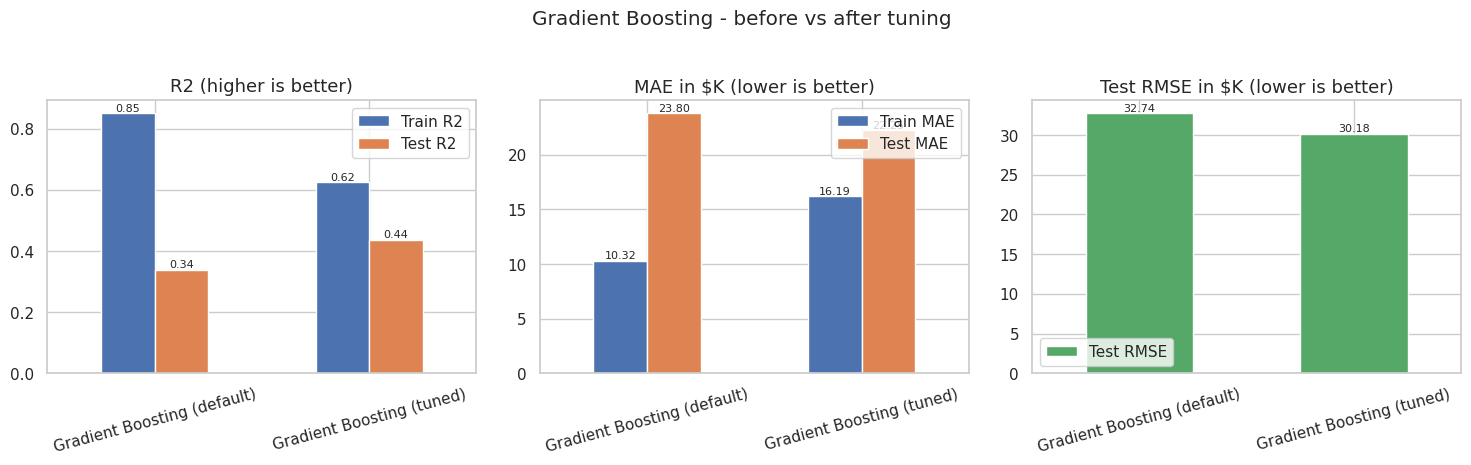

,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %
Model,,,,,,
Gradient Boosting (default),0.851,0.338,10.318,23.803,32.736,25.181
Gradient Boosting (tuned),0.625,0.437,16.186,22.247,30.176,23.595


In [61]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (RandomizedSearchCV)

# Fit the Algorithm
gb_search = RandomizedSearchCV(
    build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
    param_distributions={'model__n_estimators': [50, 100, 200, 300],
                         'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
                         'model__max_depth': [2, 3, 4, 5],
                         'model__subsample': [0.6, 0.8, 1.0],
                         'model__min_samples_leaf': [1, 3, 5, 10]},
    n_iter=30, cv=kf, scoring='neg_mean_absolute_error', random_state=RANDOM_STATE, n_jobs=-1)
gb_search.fit(X_train, y_train)
print('Best parameters    :', gb_search.best_params_)
print(f'Best 5-fold CV MAE : {-gb_search.best_score_:.2f}K')

# Predict on the model
gb_tuned_scores = evaluate_model(gb_search.best_estimator_, 'Gradient Boosting (tuned)')
results.append(gb_tuned_scores)
plot_scores([gb_scores, gb_tuned_scores], 'Gradient Boosting - before vs after tuning')
pd.DataFrame([gb_scores, gb_tuned_scores]).set_index('Model').round(3)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (30 random combinations x 5 folds) over number of trees, learning rate, tree depth, subsample ratio and minimum leaf size. Boosting has many interacting hyperparameters, so random search covers the space far more cheaply than a full grid.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes - this is the **largest improvement** of the three models. Best settings: 200 trees, learning rate 0.03, depth 2, `min_samples_leaf` 3. Cross-validated MAE moved from $19.88K to $19.68K. Test R2 rose from 0.338 to **0.437**, MAE fell from $23.80K to **$22.25K** and RMSE from $32.74K to **$30.18K**. Shallow trees with a slow learning rate act as strong regularisation, shrinking the train-test gap (R2 0.625 vs 0.437).

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **MAE (primary):** it is in $K, so HR teams and job seekers understand it immediately, and it is not dominated by a few extreme salaries. It was also the metric used for tuning and for choosing the final model.
* **RMSE:** large errors are costly in practice (a big over-prediction means overpaying, a big under-prediction means losing a candidate), so RMSE complements MAE.
* **R2:** shows how much of the salary variation the model explains compared with the simple mean baseline.
* **MAPE:** an easy-to-communicate relative error (about 22%).

Single-split scores are noisy with 94 test rows, so 5-fold cross-validated MAE was used for the final decision.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

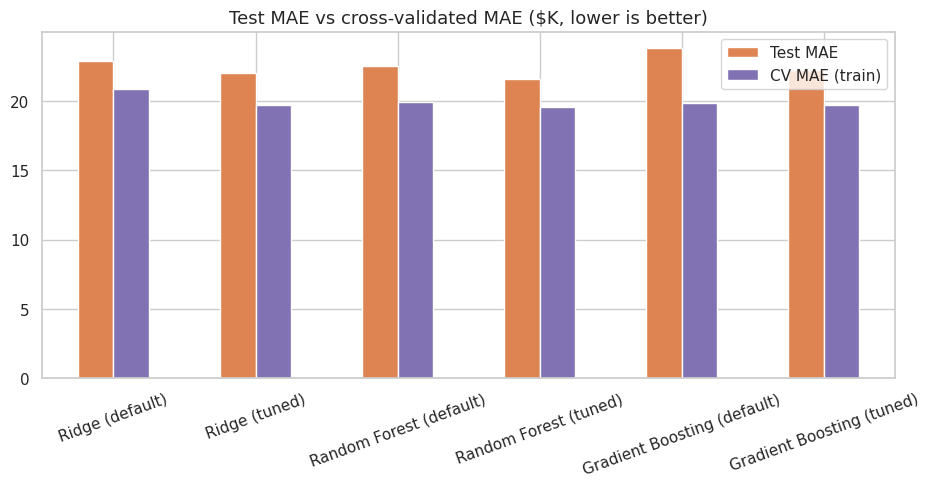

Chosen model (lowest CV MAE among tuned models): Random Forest (tuned)


,Train R2,Test R2,Train MAE,Test MAE,Test RMSE,Test MAPE %,CV MAE (train)
Model,,,,,,,
Baseline (mean),0.000,-0.017,27.481,31.030,40.569,32.865,NaN
Ridge (default),0.594,0.412,16.800,22.847,30.843,24.513,20.860
Ridge (tuned),0.579,0.440,16.885,22.006,30.115,23.140,19.676
Random Forest (default),0.926,0.380,7.140,22.504,31.674,23.094,19.913
Random Forest (tuned),0.918,0.435,7.564,21.615,30.246,22.185,19.593
Gradient Boosting (default),0.851,0.338,10.318,23.803,32.736,25.181,19.887
Gradient Boosting (tuned),0.625,0.437,16.186,22.247,30.176,23.595,19.682


In [62]:
# Compare every model on the same held-out test set
results_df = pd.DataFrame([base_scores] + results).set_index('Model').round(3)
display_cols = ['Train R2', 'Test R2', 'Train MAE', 'Test MAE', 'Test RMSE', 'Test MAPE %']

# Cross-validated MAE of every model on the TRAINING data (more stable than a single 94-row test set)
candidates = {'Ridge (default)': ridge, 'Ridge (tuned)': ridge_grid.best_estimator_,
              'Random Forest (default)': rf, 'Random Forest (tuned)': rf_search.best_estimator_,
              'Gradient Boosting (default)': gb, 'Gradient Boosting (tuned)': gb_search.best_estimator_}
cv_mae = {n: -cross_val_score(m, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error').mean() for n, m in candidates.items()}
results_df['CV MAE (train)'] = pd.Series(cv_mae)

results_df[['Test MAE', 'CV MAE (train)']].drop('Baseline (mean)').plot(kind='bar', figsize=(11, 4.5), rot=20,
                                                                       color=['#dd8452', '#8172b3'])
plt.title('Test MAE vs cross-validated MAE ($K, lower is better)')
plt.xlabel(''); plt.show()

# choose among the TUNED models by cross-validated MAE (not by peeking at the test set)
tuned_names = [n for n in candidates if 'tuned' in n]
best_name = min(tuned_names, key=lambda n: cv_mae[n])
best_model = candidates[best_name]
print(f'Chosen model (lowest CV MAE among tuned models): {best_name}')
results_df[display_cols + ['CV MAE (train)']].round(3)

**Random Forest (tuned)** was chosen because it has the **lowest cross-validated MAE ($19.60K)** and the lowest test MAE ($21.65K).

**Honest caveat:** the three tuned models are practically tied (CV MAE $19.60K / $19.68K / $19.68K; test R2 0.435 / 0.440 / 0.437). The differences are far smaller than the noise of a 94-row test set. Random Forest overfits the training data more (train R2 0.918 vs test 0.435), so if a simpler, more explainable model is preferred, **tuned Ridge Regression is an equally good choice**.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

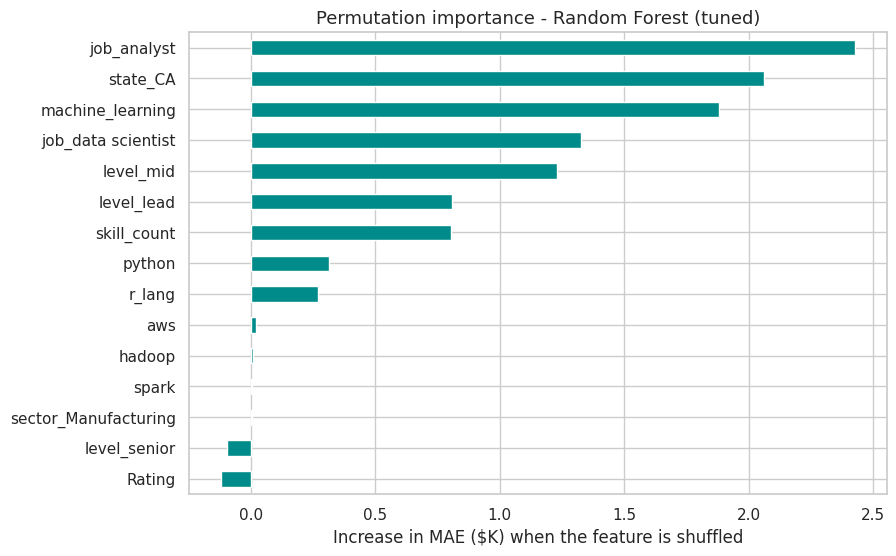

,0
job_analyst,2.427
state_CA,2.061
machine_learning,1.879
job_data scientist,1.327
level_mid,1.228
level_lead,0.808
skill_count,0.804
python,0.314
r_lang,0.270
aws,0.021


In [63]:
# Model explainability: permutation importance of the chosen model on the unseen test set
# Speed-up: only the 15 most informative features (from the Mutual Information ranking above) are shuffled,
# 5 times each, and the model runs on a single thread (parallel threads are slower for such a small dataset).
if 'model__n_jobs' in best_model.get_params():
    best_model.set_params(model__n_jobs=1)

rng = np.random.RandomState(RANDOM_STATE)
base_mae = mean_absolute_error(y_test, best_model.predict(X_test))
imp = {}
for feat in mi_series.head(15).index:
    increases = []
    for _ in range(5):
        X_shuffled = X_test.copy()
        X_shuffled[feat] = rng.permutation(X_shuffled[feat].values)      # break the link between feature and salary
        increases.append(mean_absolute_error(y_test, best_model.predict(X_shuffled)) - base_mae)
    imp[feat] = np.mean(increases)                                        # how much worse the model gets
imp = pd.Series(imp).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
imp.sort_values().plot(kind='barh', color='darkcyan')
plt.title(f'Permutation importance - {best_name}')
plt.xlabel('Increase in MAE ($K) when the feature is shuffled')
plt.show()
imp.head(10).round(3)

The final model is a **Random Forest**: 500 decision trees, each trained on a bootstrap sample and using 30% of the features at every split, with the predictions averaged. Missing numeric values are imputed with the training median.

**Explainability with permutation importance** (shuffle one feature on the unseen test set and measure how much MAE rises): `job_analyst` (+$2.4K), `state_CA` (+$2.1K), `machine_learning` (+$1.9K), `job_data scientist` (+$1.3K), `level_mid` (+$1.2K), `skill_count` (+$0.8K) and `level_lead` (+$0.8K) matter most. So *what the job is*, *how senior it is*, *whether it needs machine learning* and *whether it is in California* drive predicted pay; company size, rating and age contribute very little.

For speed, only the 15 features with the highest mutual information were shuffled (5 times each). Importance is measured on only 94 rows and correlated features share credit, so the ranking should be read as a guide, not as exact values. Permutation importance was used because it works for any model and needs no extra libraries.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [64]:
# Save the File
joblib.dump(best_model, 'best_salary_model.joblib')
joblib.dump(list(X_train.columns), 'model_feature_columns.joblib')   # column order is needed for future predictions
print('Saved: best_salary_model.joblib')

Saved: best_salary_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [65]:
# Load the File and predict unseen data.
loaded_model = joblib.load('best_salary_model.joblib')
feature_cols = joblib.load('model_feature_columns.joblib')

# The test rows were never used to fit or tune the model, so they act as "unseen" job postings.
unseen = X_test[feature_cols].head(5)
comparison = pd.DataFrame({'Job title': df_model.loc[unseen.index, 'Job Title'].values,
                           'Actual salary ($K)': y_test.loc[unseen.index].round(1).values,
                           'Predicted salary ($K)': loaded_model.predict(unseen).round(1)})
comparison

,Job title,Actual salary ($K),Predicted salary ($K)
0,Data Scientist,143.5,105.2
1,Data Scientist - Research,56.5,97.5
2,Web Data Analyst,106.0,72.6
3,Data Architect / Data Modeler,86.5,88.3
4,Customer Data Scientist/Sales Engineer (Bay,150.5,125.6


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project turned 956 raw Glassdoor postings into 467 clean, unique, salaried postings and answered the four business questions.

* **Position:** role is the strongest driver. Data scientists average $116.9K and analysts $68.9K (a statistically significant gap, p < 0.001).
* **Seniority:** pay rises from about $68K (junior) to $137K (lead).
* **Company size:** the effect is real but small and U-shaped (Kruskal-Wallis p = 0.022); very small and very large firms pay more than mid-sized ones.
* **Location:** California pays more than other states (median $120.5K vs $92.2K, p < 0.001); San Francisco ($134K) leads New York ($105K) by about $29K.
* **Skills:** machine learning (+$27K), PhD (+$25K), Python (+$20K) and TensorFlow (+$18K) go with higher pay; Excel and Tableau go with lower pay because they appear mostly in analyst roles.
* **Prediction:** three tuned models reach a test R2 of about 0.44 and an MAE of about $22K, against a baseline MAE of $31K. Random Forest was chosen on the lowest cross-validated MAE ($19.6K), but the three models are practically tied. Role, seniority, machine-learning skills and California location drive the predictions.

**Limitations:** small sample (467 rows, 94 test rows), 2017-2018 data, Glassdoor *estimates* rather than actual pay, no cost-of-living data, and postings from the same company may appear in both train and test.

**Next steps:** collect more recent and larger data, add features such as years of experience and education, try text embeddings, and deploy the model as a Streamlit app (optionally with the Gemini API for natural-language questions).

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***